---
title: "Krishna et al. (1997): the two-class holdup split in slurry bubble columns, and what it means for a reactor"
description: "Tests the paper's split of the gas holdup (dense-phase voidage scale-independent and falling with slurry concentration; large-bubble holdup slurry-independent and falling with column diameter) against the paper's own figures, and works out what the split, as the correlations encode it, does to a first-order gas-consuming reaction."
categories: [sec:F, struct:S7, tier:T1, data:tier4, phase:gas-liquid-solid]
date: 2026-11-27
---

# Krishna et al. (1997): the two-class holdup split, tested on its own figures

**Catalog ID:** `F2.2` · **Structures:** `S7` (multiphase coupling) · **Tier:** T1

Krishna, de Swart, Ellenberger, Martina and Maretto measured the gas holdup of air in
paraffin oil with up to 36 vol. % porous silica in columns of 0.10, 0.19 and 0.38 m,
and split it, by dynamic gas disengagement, into a dense phase (small bubbles in the
slurry) and a dilute phase (large bubbles). They conclude that the dense-phase
voidage depends on the slurry and not on the column, and the large-bubble holdup on
the column and not on the slurry. This page takes the numbers from the paper's own
figures and tests each half of that split, with standard errors and read errors. It
then asks what the split, as the paper's correlations encode it, means for a reactor
with a first-order gas-consuming reaction (rate constant illustrative): closed forms,
checked by a pymrm finite-volume solve.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.9"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F2.2-krishna-slurry-two-class-holdup"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page's model.py is put on sys.path by setup().
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import find_roots, observed_orders
from gallery_utils import (load_data, load_meta, cite_data, load_claims, Claims,
                           assert_check_values)
from model import (v_small, eps_df, u_df, alpha2, eps_b, eps_total, eps_b_from_total,
                   fig8_amplitude, udf_maximum, split, x_dense, conversion, d_required,
                   kH0_over_U, crossing, TwoClassReactor)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
BREAK = []   # (row, claim, clean value, broken value, caught)


def md(text):
    display(Markdown(text))

## Background

In the churn-turbulent regime a bubble column holds two gas populations. Small
bubbles travel with the liquid or slurry, which "suffers backmixing considerably"
(p. 311), and fill it to a voidage close to the one at the regime transition. Large
bubbles rise through it fast and nearly in plug flow. Krishna et al. separate the two
by shutting the gas off and following the pressure: the large bubbles leave in a few
seconds, the small ones slowly. Their conclusion (p. 315, quoted from the page image):

> The splitting of the total gas holdup ε into two parts: (1) a scale-independent,
> system- and slurry-concentration-dependent dense-phase gas holdup ε_df, and (2) a
> scale-dependent, system-and-slurry-concentration independent dilute-phase gas
> holdup ε_b is an important clue to the estimation of the gas holdup in slurry bubble
> columns.

The two halves are each stated more weakly in the text: ε_df "is virtually
independent of the column diameter" (p. 314) and "practically independent of the
column diameter" (p. 315); ε_b "is virtually independent of slurry concentration, but
is a significant function of the column diameter" (p. 315). The abstract (p. 311) says of the slurry that
"the influence on the dilute-phase gas holdup is small". This page measures each
half on the paper's own figures and reports the number beside the word.

The paper prints no reactor model. What the split implies for conversion is worked
out here with the paper's correlations and a reaction of the page's choosing.
Neighbouring pages: `F1.4` owns eq. 6's gas-liquid origin (Krishna and Ellenberger
1996); `F2.3` builds the Fischer-Tropsch reactor on eqs. 2 to 7 at one diameter;
`A2.1` owns the Danckwerts vessel used for the dispersed dense phase. Not covered:
the effect of pressure and the Reilly correlation (pp. 314-315), the disengagement
theory itself (Fig. 3), Fig. 4 (total holdup per concentration; Fig. 4a was not
digitised on this page, Fig. 4b has six overlapping series).

## The published model

| eq. | as used | code |
|---|---|---|
| 1 | $\varepsilon_b = (\varepsilon - \varepsilon_{df})/(1-\varepsilon_{df})$ (disengagement) | `eps_b_from_total` |
| 2 | $V_{small} = V_{small,0} + 0.8\,\varepsilon_s$, $V_{small,0} = 0.095$ m/s | `v_small` |
| 3 | $\varepsilon = U/V_{small}$ for $U \le U_{df}$ | `eps_total` |
| 4 | $\varepsilon_{df} = \varepsilon_{df,0} - 0.7\,\varepsilon_s$, $\varepsilon_{df,0} = 0.27$ | `eps_df` |
| 5 | $U_{df} = V_{small}\,\varepsilon_{df}$ | `u_df` |
| 6 | $\varepsilon_b = \alpha_2 D_T^{-N} (U-U_{df})^{0.58}$, $N = 0.18$ | `eps_b` |
| 7 | $\varepsilon = \varepsilon_b + \varepsilon_{df}(1-\varepsilon_b)$ for $U > U_{df}$ | `eps_total` |

$\alpha_2 = 0.268$ for low and $0.3$ for high slurry concentrations. The text prints
"ε_s < 0.10" and "ε_s > 0.16", but Fig. 8a (titled ε_s < 0.10) holds the 0.10 series
and Fig. 8b (ε_s > 0.16) both 0.16 series, so the ranges are read as ≤ and ≥; nothing
is printed in between and `alpha2` raises there. Eq. 6 is "a dimensional equation in
which SI units need to be inserted" (p. 314). Fig. 8 plots $\varepsilon_b(D_T/D_{ref})^N$
with $D_{ref} = 0.1$ m, so its lines have amplitude $\alpha_2 D_{ref}^{-N}$. The
notation list calls N the "power in the rise velocity correlation"; it is the diameter
exponent of eq. 6. ε_df is gas per dense-phase volume (eqs. 1 and 7); the small-bubble
gas per column volume is $\varepsilon_{df}(1-\varepsilon_b)$.

**The page's reactor (not in the paper).** Gas reactant consumed at a first-order rate
$k c$ per unit volume of gas, the same $k$ in both classes; no exchange between the
classes. With $\beta = 1 - U_{df}/U$ the flow share of the large bubbles,
$\varphi = \varepsilon_{df}(1-\varepsilon_b)/\varepsilon$ the dense share of the gas
holdup, $\tau = \varepsilon H/U$ the mean gas residence time and $H = H_0/(1-\varepsilon)$:
$\tau_b/\tau = (1-\varphi)/\beta$, $\tau_{df}/\tau = \varphi/(1-\beta)$, and with $D = k\tau$

$$X = \beta\,(1 - e^{-D\tau_b/\tau}) + (1-\beta)\,X_{df}(D\tau_{df}/\tau),$$

$X_{df}$ stirred ($Da/(1+Da)$), plug ($1-e^{-Da}$) or axially dispersed (Danckwerts
closed vessel, Péclet number illustrative). The required $k H_0/U = D(1-\varepsilon)/\varepsilon$.
$k$, the target conversion 0.9, the Péclet numbers and equal $k$ in both classes are
this page's choices.

## Parameters and assumptions

The printed constants and Table 1 are loaded as strings from
`krishna-1997-printed-numbers.csv` and never retyped; one dictionary `P` carries them
into every function, so a defect in one constant is one changed entry. Test condition
T of the reactor: $D_T = 0.38$ m, $U = 0.30$ m/s, $\varepsilon_s = 0.36$ ($H_0 = 1.92$ m);
companion T0: the same column without solids ($H_0 = 1.75$ m).

In [3]:
pn = load_data("krishna-1997-printed-numbers.csv", page=PAGE, dtype=str, keep_default_na=False)
PR = {r.quantity: r.value for r in pn.itertuples() if r.quantity != "H0"}       # printed strings
H0 = {(float(r.D_T), float(r.eps_s)): float(r.value) for r in pn.itertuples() if r.quantity == "H0"}
P = dict(V0=float(PR["V_small0"]), cV=float(PR["eq2_slope"]), edf0=float(PR["eps_df0"]),
         cE=float(PR["eq4_slope"]), a2_low=float(PR["alpha2_low"]), a2_high=float(PR["alpha2_high"]),
         es_low=float(PR["eps_s_alpha2_low"]), es_high=float(PR["eps_s_alpha2_high"]),
         N=float(PR["N"]), m=float(PR["eq6_exponent"]), D_ref=float(PR["D_ref"]))


def half_unit(s):
    """Half a unit of the last printed digit of the string ``s``."""
    d = len(s.split(".")[1]) if "." in s else 0
    return 0.5 * 10.0 ** (-d)


def with_(**kw):
    """The parameter set with entries replaced (a defect row)."""
    return {**P, **kw}


T = dict(U=0.30, D_T=0.38, eps_s=0.36)
T0 = dict(U=0.30, D_T=0.38, eps_s=0.0)
X_TARGET, PE_REF = 0.9, 5.0
print("printed:", {k: PR[k] for k in ("V_small0", "eq2_slope", "eps_df0", "eq4_slope",
                                      "alpha2_low", "alpha2_high", "N", "eq6_exponent", "D_ref")})
print("Table 1 H0 [m]:", H0)

printed: {'V_small0': '0.095', 'eq2_slope': '0.8', 'eps_df0': '0.27', 'eq4_slope': '0.7', 'alpha2_low': '0.268', 'alpha2_high': '0.3', 'N': '0.18', 'eq6_exponent': '0.58', 'D_ref': '0.1'}
Table 1 H0 [m]: {(0.1, 0.0): 1.6, (0.1, 0.05): 1.6, (0.1, 0.1): 1.6, (0.1, 0.16): 1.6, (0.1, 0.25): 1.6, (0.1, 0.35): 1.6, (0.19, 0.0): 1.8, (0.19, 0.33): 2.01, (0.38, 0.0): 1.75, (0.38, 0.16): 1.79, (0.38, 0.29): 1.87, (0.38, 0.36): 1.92}


## The data

Every number below comes from the page images at 300 dpi (the scan is a 300 ppi
bilevel image; its text layer substitutes digits). Each CSV stores the pixel position of
every read and its sidecar the tick calibration; the page converts pixels to values
itself, so a calibration defect is one argument.

| dataset | content | read |
|---|---|---|
| `krishna-1997-fig5-lines` | Fig. 5: the six drawn lines of total holdup at low U, 0.10 m | column crossings |
| `krishna-1997-fig6` | Fig. 6: dense-phase voidage markers, 0.38 m, four concentrations | template matching |
| `krishna-1997-fig7-line`, `-fig7-stacks` | Fig. 7: the eq. 4 line; per Table 1 group the range of marker centres | crossings; stack extents |
| `krishna-1997-fig8`, `-fig8-lines` | Fig. 8a, 8b: scaled large-bubble holdup markers and lines | template matching; crossings |
| `krishna-1997-fig9`, `-fig9-lines` | Fig. 9: total holdup markers and the eqs. 2 to 7 curves, three sets | template matching; crossings |

What the figures allow, and what they do not. Fig. 7's markers overlap in stacks, so
no marker can be counted and the page never forms a mean from a stack: it uses the
range of marker centres. At ε_s = 0 the three diameters overlap on the y-axis line and
cannot be separated. Fig. 8b's markers form one dense band; only the markers isolated
from it carry a series label (circles below the band, pluses and crosses at its edges),
which can bias those series' amplitudes, and the page says so where it uses them.
Fig. 9's template shapes are confused where markers sit on the curves, so the page
assigns each Fig. 9 marker to the nearest drawn curve instead. Fig. 6's legend glyphs
are carried as rows flagged `legend = yes` and excluded.

Borrowed numbers: `F2.3`'s holdup deviations at ε_s = 0.35 in a 0.10 m column are loaded
from its `agreement.json` for comparison in R4; `F2.3` digitised a different paper's
figure (Maretto and Krishna 1999, Fig. 2) and flags its merged origin cluster and its
own 2 U_df cut, neither of which affects the rows used here.

In [4]:
def calib(name):
    """Pixel-to-value maps of a dataset's sidecar (one panel)."""
    m = load_meta(name, page=PAGE)["acquisition"]["calibration"]
    return m


def to_values(df, cal, dx=0.0, dy=0.0, x0_px=None):
    """Values from pixel columns with the sidecar calibration; ``x0_px`` puts x = 0 there.

    ``dy`` is a calibration defect (a break row): the rows read ``dy`` px low and the y
    scale ``dy``/150 too large, as from a misplaced tick.
    """
    a, b = cal["x_value_per_px"], cal["x_offset"]
    if x0_px is not None:
        b = -a * x0_px
    y = cal["y_value_per_px"] * (df.y_px.values + dy) + cal["y_offset"]
    return a * (df.x_px.values + dx) + b, y * (1.0 + dy / 150.0)


F5 = load_data("krishna-1997-fig5-lines.csv", page=PAGE)
F6 = load_data("krishna-1997-fig6.csv", page=PAGE, dtype={"eps_s": str})
F7L = load_data("krishna-1997-fig7-line.csv", page=PAGE)
F7S = load_data("krishna-1997-fig7-stacks.csv", page=PAGE, dtype={"D_T": str})
F8 = load_data("krishna-1997-fig8.csv", page=PAGE, dtype={"D_T": str, "eps_s": str})
F8L = load_data("krishna-1997-fig8-lines.csv", page=PAGE)
F9 = load_data("krishna-1997-fig9.csv", page=PAGE)
F9L = load_data("krishna-1997-fig9-lines.csv", page=PAGE)
CAL = {k: calib(f"krishna-1997-{k}.csv") for k in ("fig5-lines", "fig6", "fig7-line", "fig9")}
cal8 = load_meta("krishna-1997-fig8.csv", page=PAGE)["acquisition"]["calibration"]
CAL["fig8a"], CAL["fig8b"] = cal8["panel_a"], cal8["panel_b"]
print(cite_data(load_meta("krishna-1997-fig6.csv", page=PAGE)))
for k, c in CAL.items():
    print(f"   {k:11s} largest tick residual: x {c['x_tick_residual_px_max']:.2f} px, "
          f"y {c['y_tick_residual_px_max']:.2f} px")
tick_worst = max(max(c["x_tick_residual_px_max"], c["y_tick_residual_px_max"]) for c in CAL.values())
sp6 = load_meta("krishna-1997-fig6.csv", page=PAGE)["acquisition"]["second_pass"]
print(f"second pass, Fig. 6: {sp6['markers']} of {sp6['of_markers']} markers re-read by bounding box; "
      f"largest eps_df difference {sp6['eps_df_difference_max']:.4f}")
n6 = int((F6.legend == "no").sum())

Krishna, R.; de Swart, J. W. A.; Ellenberger, J.; Martina, G. B.; Maretto, C. (1997) — AIChE Journal 43(2) 311-316 — doi:10.1002/aic.690430204 — digitised from Figure 6, journal p. 314 (PDF page 4)
   fig5-lines  largest tick residual: x 0.33 px, y 1.00 px
   fig6        largest tick residual: x 0.33 px, y 0.80 px
   fig7-line   largest tick residual: x 0.60 px, y 0.54 px
   fig9        largest tick residual: x 0.50 px, y 0.45 px
   fig8a       largest tick residual: x 0.81 px, y 0.30 px
   fig8b       largest tick residual: x 0.81 px, y 0.80 px
second pass, Fig. 6: 13 of 97 markers re-read by bounding box; largest eps_df difference 0.0004


## PyMRM implementation

The correlations and the reactor's closed forms are algebra in `model.py`. pymrm
enters twice. Every root (the design $D$ at $X = 0.9$, the per-gas crossing, the
maximum of $U_{df}(\varepsilon_s)$ as a check of its closed form) is located by
`pymrm.checks.find_roots` on the whole physical range, which raises unless there is
exactly one. And `TwoClassReactor` assembles the two-class reactor on $x = z/H$ from
pymrm operators: the large bubbles by first-order upwind convection
(`construct_convflux_upwind`, `construct_div` with `nu = 0`) with inlet
`{"a": 0, "b": 1, "d": 1}` and an `{"outflow": True}` outlet; the dense-phase gas by
convection and dispersion with a Danckwerts inlet `{"a": 1/Pe, "b": 1, "d": 1}`
($c - c'/Pe = 1$ with the outward normal $-x$) and a zero-gradient outlet. Each field
has its own `(n, 1)` operators, the block matrix is assembled once in CSC, and the
linear system is one `newton` step. Exit values are read on the outlet faces with
`compute_boundary_values`.

Before any result, the page's functions reproduce the independent check values
(computed by a separate script from the equations file, in `data/check_values.csv`).

In [5]:
def case(c, p=P, **kw):
    return split(c["U"], c["D_T"], c["eps_s"], p, H0=H0[(c["D_T"], c["eps_s"])], **kw)


def reactor_numbers(c, p=P, **kw):
    """Closed-form reactor numbers at one condition (dict)."""
    s = case(c, p, **kw.get("split", {}))
    out = dict(s=s)
    for mode in ("stirred", "plug", "dispersed"):
        D = d_required(s, X_TARGET, mode, PE_REF)
        out[f"D_{mode}"] = D
        out[f"k_{mode}"] = kH0_over_U(D, s) if not kw.get("H_is_H0") else D / s["eps"]
    Ds = out["D_stirred"]
    out["dense_share"] = (1 - s["beta"]) * x_dense(Ds * s["tdf"], "stirred") / X_TARGET
    D10 = 10.0 * s["eps"] / (1 - s["eps"])
    out["X10_stirred"] = conversion(D10, s, "stirred")
    out["X10_disp"] = conversion(D10, s, "dispersed", PE_REF)
    out["a_cross"] = crossing(s)
    out["X_cross"] = -np.expm1(-out["a_cross"])
    return out


RT, RT0 = reactor_numbers(T), reactor_numbers(T0)
sT, s0 = RT["s"], RT0["s"]
pT, pT0 = (T["U"], T["D_T"], T["eps_s"]), (T0["U"], T0["D_T"], T0["eps_s"])


def at(c, f, p=P, **kw):
    return float(np.atleast_1d(f(c["U"], c["D_T"], c["eps_s"], p, **kw))[0])


computed = dict(
    V_small_T=float(v_small(0.36, P)), eps_df_T=float(eps_df(0.36, P)), U_df_T=float(u_df(0.36, P)),
    eps_b_T=at(T, eps_b), eps_T=at(T, eps_total),
    V_small_T0=float(v_small(0.0, P)), eps_df_T0=float(eps_df(0.0, P)), U_df_T0=float(u_df(0.0, P)),
    eps_b_T0=at(T0, eps_b), eps_T0=at(T0, eps_total),
    alpha2_high_over_low=alpha2(0.36, P) / alpha2(0.0, P),
    fig8a_line_amplitude=fig8_amplitude(0.0, P), fig8b_line_amplitude=fig8_amplitude(0.36, P),
    diameter_factor_019=(0.19 / P["D_ref"]) ** -P["N"], diameter_factor_038=(0.38 / P["D_ref"]) ** -P["N"],
    eq4_zero_eps_s=P["edf0"] / P["cE"],
    eq4_T_halfunit_low=(P["edf0"] - half_unit(PR["eps_df0"])) - (P["cE"] + half_unit(PR["eq4_slope"])) * 0.36,
    eq4_T_halfunit_high=(P["edf0"] + half_unit(PR["eps_df0"])) - (P["cE"] - half_unit(PR["eq4_slope"])) * 0.36,
    U_df_max_eps_s=udf_maximum(P)[0], U_df_max=udf_maximum(P)[1],
    eq1_inverts_eq7_T=eps_b_from_total(at(T, eps_total), float(eps_df(0.36, P))) / at(T, eps_b),
    eq3_eq7_continuity_T=float(u_df(0.36, P) / v_small(0.36, P)) / float(eps_df(0.36, P)),
    break_alpha2_low_eps_b_T=at(T, eps_b, with_(a2_high=P["a2_low"])),
    break_alpha2_low_eps_T=at(T, eps_total, with_(a2_high=P["a2_low"])),
    break_N0_eps_b_T=at(T, eps_b, with_(N=0.0)),
    break_eq7_no_overlap_eps_T=at(T, eps_total, overlap=False),
    break_udf_reilly_U_df_T0=float(u_df(0.0, P, "reilly")),
    break_v0_fig5_U_df_T0=float(u_df(0.0, with_(V0=0.0794))),
    break_eq4_slope072_eps_df_T=float(eps_df(0.36, with_(cE=0.72))),
    tau_mean_T_s=sT["tau_mean"], tau_mean_T0_s=s0["tau_mean"],
    capacity_ratio_T0_over_T_k0=(s0["eps"] / (1 - s0["eps"])) / (sT["eps"] / (1 - sT["eps"])),
    D_required_single_plug_flow=np.log(1.0 / (1.0 - X_TARGET)),
    kH0_over_U_required_ratio_T_over_T0_cstr=RT["k_stirred"] / RT0["k_stirred"],
    break_tau_df_no_overlap_D_required_cstr_T0=d_required(case(T0, overlap_in_tau=False)),
    break_udf_reilly_D_required_cstr_T0=d_required(case(T0, udf_form="reilly")),
    break_alpha2_low_D_required_cstr_T=d_required(case(T, with_(a2_high=P["a2_low"]))),
    break_H_equals_H0_kH0_over_U_required_cstr_T=RT["D_stirred"] / sT["eps"],
    X_dense_disp_T0_at_root=float(x_dense(RT0["D_dispersed"] * s0["tdf"], "dispersed", PE_REF)),
)
for tag, s_ in (("0.05", 0.05), ("0.10", 0.10), ("0.16", 0.16), ("0.25", 0.25), ("0.29", 0.29),
                ("0.33", 0.33), ("0.35", 0.35)):
    if tag != "0.29" and tag != "0.33":
        computed[f"V_small_eq2_es{tag}"] = float(v_small(s_, P))
    computed[f"eps_df_eq4_es{tag}"] = float(eps_df(s_, P))
    computed[f"U_df_eq5_es{tag}"] = float(u_df(s_, P))
computed["eps_b_T_over_T0"] = computed["eps_b_T"] / computed["eps_b_T0"]
computed["eps_df_T0_over_T"] = computed["eps_df_T0"] / computed["eps_df_T"]
computed["eps_T0_over_T"] = computed["eps_T0"] / computed["eps_T"]
for sfx, R in (("T", RT), ("T0", RT0)):
    s = R["s"]
    computed.update({f"beta_{sfx}": s["beta"], f"phi_dense_holdup_share_{sfx}": s["phi"],
                     f"dense_flow_share_{sfx}": 1 - s["beta"], f"tau_b_over_tau_mean_{sfx}": s["tb"],
                     f"tau_df_over_tau_mean_{sfx}": s["tdf"], f"r_tau_df_over_tau_b_{sfx}": s["r"],
                     f"rtd_identity_{sfx}": s["beta"] * s["tb"] + (1 - s["beta"]) * s["tdf"],
                     f"D_required_cstr_{sfx}": R["D_stirred"], f"kH0_over_U_required_cstr_{sfx}": R["k_stirred"],
                     f"D_required_pfr_{sfx}": R["D_plug"], f"kH0_over_U_required_pfr_{sfx}": R["k_plug"],
                     f"D_required_disp_{sfx}": R["D_dispersed"], f"kH0_over_U_required_disp_{sfx}": R["k_dispersed"],
                     f"penalty_over_plug_flow_cstr_{sfx}": R["D_stirred"] / np.log(10.0),
                     f"dense_conversion_share_at_target_cstr_{sfx}": R["dense_share"],
                     f"cstr_minus_pfr_D_required_{sfx}": R["D_stirred"] - R["D_plug"],
                     f"X_at_kH0U10_cstr_{sfx}": R["X10_stirred"], f"X_at_kH0U10_disp_{sfx}": R["X10_disp"],
                     f"crossing_k_tau_b_{sfx}": R["a_cross"], f"crossing_conversion_{sfx}": R["X_cross"]})
CHECK = assert_check_values(computed, page=PAGE)
# data claims (registered after the check values, as the page contract asks)
claims.bound("tick_residual_worst_px", tick_worst, max=2.0, basis="chosen", structural=True,
             note="calibration quality of the committed reads (plan V4: below 2 px); no model defect moves it")
claims.bound("second_pass_fig6_max_diff", sp6["eps_df_difference_max"], max=0.002, basis="chosen",
             structural=True, note="against the sidecar read error of 0.002; a property of the committed data")
claims.exact("check_values_agree", len(CHECK), structural=True,
             note="rows of the committed check values the page reproduces; a failing row raises before this line")
claims.exact("fig6_markers", n6, structural=True, note="rows of the committed CSV that are data")
claims.exact("fig9_markers", len(F9), structural=True, note="rows of the committed CSV")
claims.exact("fig8_markers", len(F8), structural=True, note="rows of the committed CSV")

check values: 101 of 101 agree, worst relative 8.6e-12


In [6]:
ROWS = [
    "alpha2 0.268 for eps_s >= 0.16",
    "D_ref ignored in the Fig. 8 line amplitude",
    "N = 0 in eq. 6",
    "eq. 7 without the (1 - eps_b) overlap",
    "U_df in the Reilly form V eps_df (1 - eps_df)",
    "V_small,0 = 0.0794 (the Fig. 5 line)",
    "eq. 4 slope 0.72",
    "eps_df,0 = 0.25",
    "dense gas per column volume taken as eps_df",
    "H = H0 (bed expansion ignored)",
    "Fig. 5 x calibration from the axis line",
    "Fig. 6, Fig. 7 and Fig. 9 read 3 px low with a 2 % y scale",
    "Fig. 6 legend unmasked",
    "Fig. 7 glyph half heights ignored",
    "Fig. 7 read error 0.015 (a marker radius) instead of 0.003",
    "constancy threshold read as 0.2 m/s",
    "pymrm solve at the stirred-dense-phase root",
    "Fig. 7 eps_s 0.16 diameter labels swapped",
    "Fig. 8 read 3 px low with a 2 % y scale",
    "Fig. 8 labels dropped (all panel-a markers pooled as 0.10 m)",
    "large-bubble outlet zero gradient instead of outflow",
    "dense-phase inlet sign flipped",
    "cell Peclet number held fixed instead of the column Peclet number",
    "round-off companion against the next coarser grid",
]
claims.define_rows(ROWS)


def record(row, metrics, names=None):
    """Record a defect row against every claim it recomputed (or ``names``)."""
    for k, v in metrics.items():
        if k in claims.metrics and (names is None or k in names):
            caught = claims.breaks(row, k, v)
            BREAK.append((row, k, claims[k], v, caught))

## Results

### R1. The printed constants against what the paper draws

**Fig. 5** draws, for the 0.10 m column at low U, one line through the origin per
concentration; eq. 2 says their inverse slopes are $V_{small} = 0.095 + 0.8\,\varepsilon_s$.
Each line's $V_{small}$ is the least-squares inverse slope through the origin of its
column crossings (a fit, one per line).

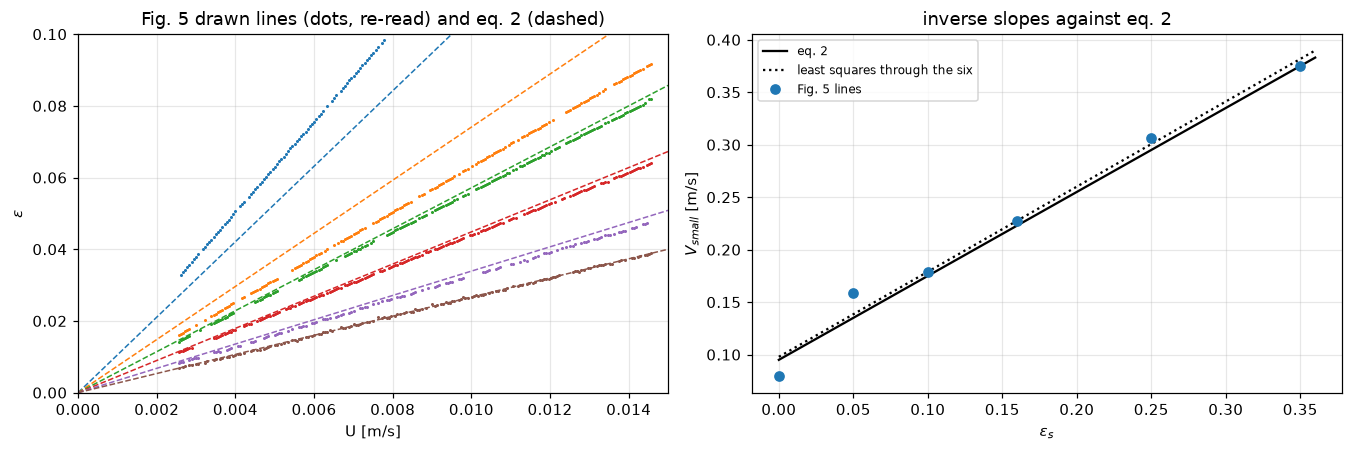

| ε_s | Fig. 5 line V_small [m/s] | eq. 2 | gap |
|---|---|---|---|
| 0.0 | 0.0793 | 0.095 | -16.6 % |
| 0.05 | 0.1586 | 0.135 | +17.5 % |
| 0.1 | 0.1784 | 0.175 | +1.9 % |
| 0.16 | 0.2276 | 0.223 | +2.1 % |
| 0.25 | 0.3068 | 0.295 | +4.0 % |
| 0.35 | 0.3746 | 0.375 | -0.1 % |

The least-squares line through the six inverse slopes is 0.0979 ± 0.0096 + (0.811 ± 0.050) ε_s m/s (standard errors from the scatter of the six); its intercept is +0.30 standard errors from eq. 2's 0.095. Eq. 2 is a straight line that the six drawn lines do not all lie on: the ε_s = 0 line is -16.6 % and the 0.05 line +17.5 % off it, the other four within 4.0 %. Taking x = 0 at the drawn axis line instead of the ticks moves the ε_s = 0 slope by +1.1 %, far less than the first two gaps.

In [7]:
ES5 = [0.0, 0.05, 0.10, 0.16, 0.25, 0.35]
AXIS5 = 273.0     # column of the drawn y-axis line of Fig. 5 (sidecar note)
TAG = {0.0: "0", 0.05: "005", 0.10: "010", 0.16: "016", 0.25: "025", 0.29: "029", 0.33: "033",
       0.35: "035", 0.36: "036"}


def study_fig5(p=P, x0_px=None):
    U, eps = to_values(F5, CAL["fig5-lines"], x0_px=x0_px)
    out = {}
    V = []
    for s in ES5:
        k = np.isclose(F5.eps_s.values, s)
        v = np.sum(U[k] ** 2) / np.sum(U[k] * eps[k])
        V.append(v)
        out[f"fig5_V_small_es{TAG[s]}"] = v
        out[f"fig5_gap_eq2_es{TAG[s]}"] = v / float(v_small(s, p)) - 1.0
    A = np.vstack([np.ones(6), ES5]).T
    coef, res, *_ = np.linalg.lstsq(A, V, rcond=None)
    sig2 = res[0] / (6 - 2)
    cov = sig2 * np.linalg.inv(A.T @ A)
    out.update(fig5_fit_intercept=coef[0], fig5_fit_slope=coef[1],
               fig5_fit_intercept_se=np.sqrt(cov[0, 0]), fig5_fit_slope_se=np.sqrt(cov[1, 1]))
    out["fig5_fit_intercept_z_vs_eq2"] = (coef[0] - p["V0"]) / np.sqrt(cov[0, 0])
    # sensitivity: the eps_s = 0 slope with x = 0 at the drawn axis line instead of the ticks
    Ua, _ = to_values(F5, CAL["fig5-lines"], x0_px=AXIS5)
    k = np.isclose(F5.eps_s.values, 0.0)
    out["fig5_xcal_shift_es0"] = (np.sum(Ua[k] ** 2) / np.sum(Ua[k] * eps[k])) / V[0] - 1.0
    return out


R1a = study_fig5()
for k, v in R1a.items():
    claims.value(k, v, rtol=1e-6)
fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.2))
UU = np.linspace(0, 0.015, 50)
for s in ES5:
    k = np.isclose(F5.eps_s.values, s)
    U5, e5 = to_values(F5[k], CAL["fig5-lines"])
    l, = ax[0].plot(U5, e5, ".", ms=2)
    ax[0].plot(UU, UU / float(v_small(s, P)), "--", color=l.get_color(), lw=1)
ax[0].set(xlabel="U [m/s]", ylabel=r"$\epsilon$", ylim=(0, 0.1), xlim=(0, 0.015),
          title="Fig. 5 drawn lines (dots, re-read) and eq. 2 (dashed)")
ax[1].errorbar(ES5, [R1a[f"fig5_V_small_es{TAG[s]}"] for s in ES5], fmt="o", label="Fig. 5 lines")
ee = np.linspace(0, 0.36, 10)
ax[1].plot(ee, v_small(ee, P), "k-", label="eq. 2")
ax[1].plot(ee, R1a["fig5_fit_intercept"] + R1a["fig5_fit_slope"] * ee, "k:", label="least squares through the six")
ax[1].set(xlabel=r"$\epsilon_s$", ylabel=r"$V_{small}$ [m/s]", title="inverse slopes against eq. 2")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
md("| ε_s | Fig. 5 line V_small [m/s] | eq. 2 | gap |\n|---|---|---|---|\n" + "\n".join(
    f"| {s} | {R1a[f'fig5_V_small_es{TAG[s]}']:.4f} | {float(v_small(s, P)):.3f} | "
    f"{R1a[f'fig5_gap_eq2_es{TAG[s]}'] * 100:+.1f} % |" for s in ES5))
md(f"The least-squares line through the six inverse slopes is "
   f"{R1a['fig5_fit_intercept']:.4f} ± {R1a['fig5_fit_intercept_se']:.4f} + "
   f"({R1a['fig5_fit_slope']:.3f} ± {R1a['fig5_fit_slope_se']:.3f}) ε_s m/s (standard errors from the "
   f"scatter of the six); its intercept is {R1a['fig5_fit_intercept_z_vs_eq2']:+.2f} standard errors from "
   f"eq. 2's {PR['V_small0']}. Eq. 2 is a straight line that the six drawn lines do not all lie on: the "
   f"ε_s = 0 line is {R1a['fig5_gap_eq2_es0'] * 100:+.1f} % and the 0.05 line "
   f"{R1a['fig5_gap_eq2_es005'] * 100:+.1f} % off it, the other four within "
   f"{max(abs(R1a[f'fig5_gap_eq2_es{TAG[s]}']) for s in ES5[2:]) * 100:.1f} %. Taking x = 0 at the drawn "
   f"axis line instead of the ticks moves the ε_s = 0 slope by {R1a['fig5_xcal_shift_es0'] * 100:+.1f} %, "
   f"far less than the first two gaps.")

**Fig. 7 and Fig. 8 lines.** The drawn eq. 4 line in Fig. 7 (fit to its crossings) and
the Fig. 8 lines (amplitude at the printed exponent 0.58, from the crossings) against
the printed constants; a printed constant is compared in half-units of its last
printed digit.

In [8]:
def study_lines(p=P, D_ref=None, dy7=0.0, dy8=0.0, dy9=0.0):
    out = {}
    e7, y7 = to_values(F7L, CAL["fig7-line"], dy=dy7)
    c = np.polyfit(e7, y7, 1)
    out["fig7_line_intercept"], out["fig7_line_slope"] = c[1], c[0]
    out["fig7_intercept_halfunits"] = (c[1] - p["edf0"]) / half_unit(PR["eps_df0"])
    out["fig7_slope_halfunits"] = (-c[0] - p["cE"]) / half_unit(PR["eq4_slope"])
    out["fig7_line_at_036"] = np.polyval(c, 0.36)
    for pan, es in (("a", 0.0), ("b", 0.36)):
        k = F8L.panel.values == pan
        x, y = to_values(F8L[k], CAL[f"fig8{pan}"], dy=dy8)
        A = np.exp(np.mean(np.log(y) - p["m"] * np.log(x)))
        out[f"fig8{pan}_line_amp_read"] = A
        out[f"fig8{pan}_line_gap_E8"] = A / fig8_amplitude(es, p, D_ref) - 1.0
    for es, D in ((0.35, 0.10), (0.0, 0.19), (0.36, 0.38)):
        k = np.isclose(F9L.eps_s.values, es)
        U, e = to_values(F9L[k], CAL["fig9"], dy=dy9)
        dev = e - eps_total(U, D, es, p)
        out[f"fig9_curve_median_dev_px_es{TAG[es]}"] = np.median(dev) / abs(CAL["fig9"]["y_value_per_px"])
        q = with_(a2_low=p["a2_high"], a2_high=p["a2_low"])
        dev2 = e - eps_total(U, D, es, q)
        out[f"fig9_curve_median_dev_px_swapped_es{TAG[es]}"] = np.median(dev2) / abs(CAL["fig9"]["y_value_per_px"])
    out["fig9_curve_worst_median_px"] = max(abs(out[f"fig9_curve_median_dev_px_es{TAG[e]}"]) for e in (0.35, 0.0, 0.36))
    return out


R1b = study_lines()
for k, v in R1b.items():
    if k != "fig9_curve_worst_median_px":
        claims.value(k, v, rtol=1e-6)
worst9 = R1b["fig9_curve_worst_median_px"]
claims.bound("fig9_curve_worst_median_px", worst9, max=3.0, basis="chosen",
             note="plan stop rule: a Fig. 9 curve more than 3 px off eqs. 2 to 7 means other constants were drawn")
if worst9 > 3.0:
    raise RuntimeError("Fig. 9 curves are not eqs. 2 to 7 with the printed constants")
es_star, udf_star = udf_maximum(P)
dU = lambda e: P["cV"] * eps_df(e, P) - P["cE"] * v_small(e, P)      # dU_df/deps_s
rr = find_roots(dU, 0.0, P["edf0"] / P["cE"], n_scan=64)
assert len(rr["roots"]) == 1
claims.value("udf_max_eps_s", es_star, rtol=1e-9)
claims.value("udf_max", udf_star, rtol=1e-9)
claims.bound("udf_max_root_vs_closed_form", abs(rr["roots"][0] - es_star), max=1e-10, basis="tolerance",
             structural=True, note="two exact routes to one root (closed form; find_roots, xtol 1e-12, on the "
             "analytic derivative): an identity no parameter defect separates")
md(f"Fig. 7's line is {R1b['fig7_line_intercept']:.4f} {R1b['fig7_line_slope']:+.4f} ε_s: "
   f"{R1b['fig7_intercept_halfunits']:+.2f} half-units of the printed 0.27 and "
   f"{R1b['fig7_slope_halfunits']:+.2f} of 0.7, so the drawn line is eq. 4 as printed. At ε_s = 0.36 the "
   f"printed precision brackets eq. 4 between {computed['eq4_T_halfunit_low']:.3f} and "
   f"{computed['eq4_T_halfunit_high']:.3f}, around its value {float(eps_df(0.36, P)):.3f}: the half-unit of "
   f"0.7 times 0.36 equals the value itself; the drawn line gives {R1b['fig7_line_at_036']:.4f}. "
   f"The Fig. 8 lines read {R1b['fig8a_line_amp_read']:.4f} and {R1b['fig8b_line_amp_read']:.4f} against "
   f"α₂ D_ref^-N = {fig8_amplitude(0.0, P):.4f} and {fig8_amplitude(0.36, P):.4f} "
   f"({R1b['fig8a_line_gap_E8'] * 100:+.2f} % and {R1b['fig8b_line_gap_E8'] * 100:+.2f} %), which confirms "
   f"D_ref = 0.1 m and Fig. 8b's borrowed x calibration. The Fig. 9 curves sit "
   f"{R1b['fig9_curve_median_dev_px_es035']:+.2f}, {R1b['fig9_curve_median_dev_px_es0']:+.2f} and "
   f"{R1b['fig9_curve_median_dev_px_es036']:+.2f} px (median) from eqs. 2 to 7 with α₂ 0.3, 0.268, 0.3 for "
   f"the sets ε_s 0.35, 0, 0.36; with α₂ swapped they would be "
   f"{R1b['fig9_curve_median_dev_px_swapped_es035']:+.1f}, {R1b['fig9_curve_median_dev_px_swapped_es0']:+.1f} "
   f"and {R1b['fig9_curve_median_dev_px_swapped_es036']:+.1f} px off, so the drawn α₂ is the printed one.\n\n"
   f"A consequence the paper does not state: eqs. 2, 4 and 5 make $U_{{df}}$ rise and then fall with solids, "
   f"with a maximum {udf_star:.4f} m/s at ε_s = {es_star:.4f} (closed form; `find_roots` on the derivative "
   f"agrees to below 1e-10).")

Fig. 7's line is 0.2705 -0.7092 ε_s: +0.10 half-units of the printed 0.27 and +0.18 of 0.7, so the drawn line is eq. 4 as printed. At ε_s = 0.36 the printed precision brackets eq. 4 between -0.005 and 0.041, around its value 0.018: the half-unit of 0.7 times 0.36 equals the value itself; the drawn line gives 0.0152. The Fig. 8 lines read 0.4042 and 0.4536 against α₂ D_ref^-N = 0.4056 and 0.4541 (-0.35 % and -0.11 %), which confirms D_ref = 0.1 m and Fig. 8b's borrowed x calibration. The Fig. 9 curves sit +0.03, -1.71 and -0.25 px (median) from eqs. 2 to 7 with α₂ 0.3, 0.268, 0.3 for the sets ε_s 0.35, 0, 0.36; with α₂ swapped they would be +22.5, -16.2 and +16.4 px off, so the drawn α₂ is the printed one.

A consequence the paper does not state: eqs. 2, 4 and 5 make $U_{df}$ rise and then fall with solids, with a maximum 0.0356 m/s at ε_s = 0.1335 (closed form; `find_roots` on the derivative agrees to below 1e-10).

### R2. Dense phase: does ε_df follow eq. 4, and is it independent of the column?

Fig. 6 gives ε_df against U in the 0.38 m column at four concentrations; per series the
mean with its standard error, the residual against eq. 4 in standard errors, and the
slope dε_df/dU with its standard error (the paper: "approximately constant ... exceeding
about 0.1 m/s", p. 314). Fig. 7 gives per Table 1 group only a range of marker centres.

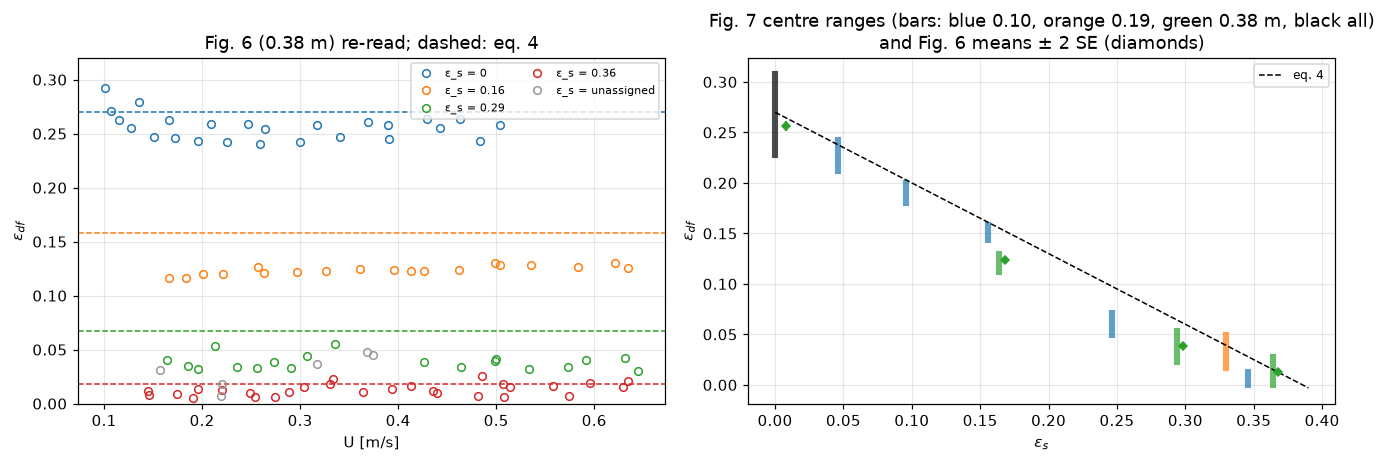

| ε_s | n | Fig. 6 mean ± SE | eq. 4 | residual | in SE | slope dε_df/dU [s/m] | t |
|---|---|---|---|---|---|---|---|
| 0 | 25 | 0.2563 ± 0.0025 | 0.270 | -0.0137 | -5.5 | -0.0279 | -1.5 |
| 0.16 | 19 | 0.1238 ± 0.0009 | 0.158 | -0.0342 | -36.5 | +0.0221 | +5.7 |
| 0.29 | 19 | 0.0384 ± 0.0016 | 0.067 | -0.0286 | -17.9 | -0.0063 | -0.6 |
| 0.36 | 28 | 0.0130 ± 0.0010 | 0.018 | -0.0050 | -4.9 | +0.0137 | +2.2 |

**Against eq. 4.** At 0.38 m the Fig. 6 means sit below eq. 4 in 4 of 4 series, by 0.0137 at ε_s = 0 and by 0.0342, 0.0286, 0.0050 at 0.16, 0.29, 0.36 (a relative 22 % at 0.16). Of the 9 single-diameter Fig. 7 groups, 5 have eq. 4 inside their centre range widened by the read error. A free line through the four 0.38 m means is 0.247 -0.688 ε_s (a comparison, not a replacement for eq. 4).

**Constancy above 0.1 m/s.** The Fig. 6 slopes are small, but at ε_s = 0.16 the slope is +5.7 standard errors from zero: +0.0110 in ε_df over 0.5 m/s, against a mean of 0.124. "Approximately constant" holds to that size.

**Diameter independence.** At ε_s = 0.16 the 0.10 m circles of Fig. 7 have centres from 0.1436 to 0.1583 and the 0.38 m diamonds from 0.1122 to 0.1299; Fig. 6's 0.38 m mean is 0.1238. The lowest 0.10 m centre is 0.0198 above the 0.38 m mean, 0.0149 after subtracting the Fig. 7 read error and two Fig. 6 standard errors: the visible centres of the two diameters are disjoint at this concentration, and eq. 4 (0.158) lies inside the 0.10 m range and outside the 0.38 m range (each widened by the read error). At ε_s = 0 the three diameters overlap in one stack on the axis (centres 0.228 to 0.308) and cannot be separated, so the figures compare the diameters at one concentration. There the difference is 16 % of the 0.38 m value, where the paper writes "virtually independent of the column diameter". One pair of groups does not show that the diameter is the cause: the 0.10 m column's own ε_s = 0.25 group misses eq. 4 by 0.0207 after the read error, as much as the gap, and a 0.10 m circle inside the solid mass of 0.38 m diamonds could not be seen (the visible 0.10 m centres span 0.0148; the other three isolated 0.10 m stacks span 0.0207 to 0.0302).

In [9]:
ES6 = ["0", "0.16", "0.29", "0.36"]
ERR7 = 0.003      # Fig. 7 read error of a centre-range end (sidecar)


def study_dense(p=P, dy6=0.0, legend=False, glyph=True, swap016=False, err7=ERR7, u_min=None):
    out = {}
    d = F6 if legend else F6[F6.legend == "no"]
    lab = d.eps_s.values.copy()
    if legend:
        lab[d.legend.values == "yes"] = "0"     # legend glyphs counted as data of the top band
    U, e = to_values(d, CAL["fig6"], dy=dy6)
    for s in ES6:
        k = lab == s
        n = int(k.sum())
        m, se = e[k].mean(), e[k].std(ddof=1) / np.sqrt(n)
        ks = k & (U > (float(PR["U_constancy"]) if u_min is None else u_min) - 0.005)
        b = np.polyfit(U[ks], e[ks], 1, cov=True)
        tag = TAG[float(s)]
        out[f"fig6_n_es{tag}"] = n
        out[f"fig6_mean_es{tag}"] = m
        out[f"fig6_se_es{tag}"] = se
        out[f"fig6_minus_eq4_es{tag}"] = m - float(eps_df(float(s), p))
        out[f"fig6_z_vs_eq4_es{tag}"] = (m - float(eps_df(float(s), p))) / se
        out[f"fig6_slope_es{tag}"] = b[0][0]
        out[f"fig6_slope_t_es{tag}"] = b[0][0] / np.sqrt(b[1][0, 0])
    st = F7S.copy()
    cal = CAL["fig7-line"]
    half = dict(circle=10.5, diamond=13.0, square=11.5, mixed=11.0)
    if not glyph:
        st["centre_low"] = cal["y_value_per_px"] * st.row_bottom + cal["y_offset"]
        st["centre_high"] = cal["y_value_per_px"] * st.row_top + cal["y_offset"]
        st.loc[st.eps_s == 0.16, ["centre_low", "centre_high"]] = F7S.loc[F7S.eps_s == 0.16, ["centre_low", "centre_high"]].values
    if swap016:
        k = st.eps_s == 0.16
        st.loc[k, "D_T"] = st.loc[k, "D_T"].map({"0.10": "0.38", "0.38": "0.10"})
    dist = []
    for r in st[st.D_T != "all"].itertuples():
        lo = 0.0 if r.on_axis else r.centre_low - err7
        hi = r.centre_high + err7
        e4 = float(eps_df(r.eps_s, p))
        dist.append(min(e4 - lo, hi - e4))
        out[f"fig7_eq4_distance_D{r.D_T}_es{TAG[r.eps_s]}"] = dist[-1]
    out["fig7_dist"] = np.array(dist)
    out["fig7_groups_eq4_inside"] = int((out["fig7_dist"] > 0).sum())
    c10 = st[(st.eps_s == 0.16) & (st.D_T == "0.10")].iloc[0]
    c38 = st[(st.eps_s == 0.16) & (st.D_T == "0.38")].iloc[0]
    out["fig7_016_D010_low"], out["fig7_016_D010_high"] = c10.centre_low, c10.centre_high
    out["fig7_016_D038_low"], out["fig7_016_D038_high"] = c38.centre_low, c38.centre_high
    # 0.10 m stack against the 0.38 m Fig. 6 mean: gap after both read errors
    out["dense_016_gap_D010_minus_fig6"] = c10.centre_low - out["fig6_mean_es016"]
    out["dense_016_margin"] = (out["dense_016_gap_D010_minus_fig6"] - err7 - 2 * out["fig6_se_es016"])
    out["dense_016_eq4_minus_fig6"] = float(eps_df(0.16, p)) - out["fig6_mean_es016"]
    c25 = st[(st.eps_s == 0.25) & (st.D_T == "0.10")].iloc[0]
    out["dense_025_D010_eq4_miss"] = float(eps_df(0.25, p)) - (c25.centre_high + err7)
    spans = {r.eps_s: r.centre_high - r.centre_low for r in st[(st.D_T == "0.10") & st.eps_s.isin([0.05, 0.10, 0.25])].itertuples()}
    out["fig7_016_D010_span"] = c10.centre_high - c10.centre_low
    out["fig7_D010_span_min"], out["fig7_D010_span_max"] = min(spans.values()), max(spans.values())
    a0 = st[st.D_T == "all"].iloc[0]
    out["fig7_es0_low"], out["fig7_es0_high"] = a0.centre_low, a0.centre_high
    out["fig6_series_below_eq4"] = int(sum(out[f"fig6_z_vs_eq4_es{TAG[float(s)]}"] < 0 for s in ES6))
    gm = [out[f"fig6_mean_es{TAG[float(s)]}"] for s in ES6]
    c, cov = np.polyfit([float(s) for s in ES6], gm, 1, cov=True)
    out.update(fig6_fit_intercept=c[1], fig6_fit_slope=c[0], fig6_fit_slope_se=np.sqrt(cov[0, 0]))
    return out


R2 = study_dense()
NOTE_N = "count of committed labelled reads; no model or calibration defect changes which read carries which label"
for k, v in R2.items():
    if k.startswith("fig6_n_"):
        claims.exact(k, v, structural=k != "fig6_n_es0", note=NOTE_N)
    elif k not in ("fig7_dist", "dense_016_margin", "fig7_groups_eq4_inside", "fig6_series_below_eq4"):
        claims.value(k, v, rtol=1e-6)
n7 = claims.count("fig7_groups_eq4_inside", R2["fig7_dist"], 0.0, min_margin=1e-4,
                  note="Fig. 7 single-diameter groups whose centre range (+-0.003) contains eq. 4; margin = nearest end")
n7_tot = len(R2["fig7_dist"])
claims.bound("dense_016_margin", R2["dense_016_margin"], min=0.0, basis="chosen",
             note="disjoint after the Fig. 7 read error and two Fig. 6 standard errors")

fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.3))
d6 = F6[F6.legend == "no"]
U6, e6 = to_values(d6, CAL["fig6"])
for s, col in zip(ES6 + ["unassigned"], ["C0", "C1", "C2", "C3", "0.6"]):
    k = d6.eps_s.values == s
    ax[0].plot(U6[k], e6[k], "o", mfc="none", color=col, ms=5, label=f"ε_s = {s}")
    if s != "unassigned":
        ax[0].axhline(float(eps_df(float(s), P)), color=col, ls="--", lw=1)
ax[0].set(xlabel="U [m/s]", ylabel=r"$\epsilon_{df}$", title="Fig. 6 (0.38 m) re-read; dashed: eq. 4", ylim=(0, 0.32))
ax[0].legend(fontsize=7, ncol=2)
for r in F7S.itertuples():
    col = {"0.10": "C0", "0.19": "C1", "0.38": "C2", "all": "k"}[r.D_T]
    off = {"0.10": -0.004, "0.19": 0.0, "0.38": 0.004, "all": 0.0}[r.D_T]
    ax[1].plot([r.eps_s + off] * 2, [0 if r.on_axis else r.centre_low, r.centre_high], "-", color=col, lw=4, alpha=0.7)
for s in ES6:
    ax[1].errorbar(float(s) + 0.008, R2[f"fig6_mean_es{TAG[float(s)]}"], yerr=2 * R2[f"fig6_se_es{TAG[float(s)]}"],
                   fmt="D", color="C2", ms=4)
ee = np.linspace(0, 0.39, 10)
ax[1].plot(ee, eps_df(ee, P), "k--", lw=1, label="eq. 4")
ax[1].set(xlabel=r"$\epsilon_s$", ylabel=r"$\epsilon_{df}$",
          title="Fig. 7 centre ranges (bars: blue 0.10, orange 0.19, green 0.38 m, black all)\nand Fig. 6 means ± 2 SE (diamonds)")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
md("| ε_s | n | Fig. 6 mean ± SE | eq. 4 | residual | in SE | slope dε_df/dU [s/m] | t |\n|---|---|---|---|---|---|---|---|\n"
   + "\n".join(f"| {s} | {R2[f'fig6_n_es{TAG[float(s)]}']} | {R2[f'fig6_mean_es{TAG[float(s)]}']:.4f} ± "
               f"{R2[f'fig6_se_es{TAG[float(s)]}']:.4f} | {float(eps_df(float(s), P)):.3f} | "
               f"{R2[f'fig6_minus_eq4_es{TAG[float(s)]}']:+.4f} | {R2[f'fig6_z_vs_eq4_es{TAG[float(s)]}']:+.1f} | "
               f"{R2[f'fig6_slope_es{TAG[float(s)]}']:+.4f} | {R2[f'fig6_slope_t_es{TAG[float(s)]}']:+.1f} |" for s in ES6))
n_below = claims.count("fig6_series_below_eq4", [R2[f"fig6_z_vs_eq4_es{TAG[float(s)]}"] for s in ES6], 0.0,
                       above=False, min_margin=2.0, relative=False,
                       note="Fig. 6 series whose mean is below eq. 4; margin in standard errors")
md(f"**Against eq. 4.** At 0.38 m the Fig. 6 means sit below eq. 4 in {n_below} of {len(ES6)} series, by "
   f"{-R2['fig6_minus_eq4_es0']:.4f} at ε_s = 0 and by {-R2['fig6_minus_eq4_es016']:.4f}, "
   f"{-R2['fig6_minus_eq4_es029']:.4f}, {-R2['fig6_minus_eq4_es036']:.4f} at 0.16, 0.29, 0.36 "
   f"(a relative {-R2['fig6_minus_eq4_es016'] / float(eps_df(0.16, P)) * 100:.0f} % at 0.16). Of the "
   f"{n7_tot} single-diameter Fig. 7 groups, {n7} have eq. 4 inside their centre range widened by the read "
   f"error. A free line through the four 0.38 m means is {R2['fig6_fit_intercept']:.3f} "
   f"{R2['fig6_fit_slope']:+.3f} ε_s (a comparison, not a replacement for eq. 4).\n\n"
   f"**Constancy above 0.1 m/s.** The Fig. 6 slopes are small, but at ε_s = 0.16 the slope is "
   f"{R2['fig6_slope_t_es016']:+.1f} standard errors from zero: "
   f"{R2['fig6_slope_es016'] * 0.5:+.4f} in ε_df over 0.5 m/s, against a mean of {R2['fig6_mean_es016']:.3f}. "
   f"\"Approximately constant\" holds to that size.\n\n"
   f"**Diameter independence.** At ε_s = 0.16 the 0.10 m circles of Fig. 7 have centres from "
   f"{R2['fig7_016_D010_low']:.4f} to {R2['fig7_016_D010_high']:.4f} and the 0.38 m diamonds from "
   f"{R2['fig7_016_D038_low']:.4f} to {R2['fig7_016_D038_high']:.4f}; Fig. 6's 0.38 m mean is "
   f"{R2['fig6_mean_es016']:.4f}. The lowest 0.10 m centre is {R2['dense_016_gap_D010_minus_fig6']:.4f} above "
   f"the 0.38 m mean, {R2['dense_016_margin']:.4f} after subtracting the Fig. 7 read error and two Fig. 6 "
   f"standard errors: the visible centres of the two diameters are {'disjoint' if R2['dense_016_margin'] > 0 else 'not separated'} at "
   f"this concentration, and eq. 4 ({float(eps_df(0.16, P)):.3f}) lies "
   f"{'inside' if R2['fig7_eq4_distance_D0.10_es016'] > 0 else 'outside'} the 0.10 m range and "
   f"{'inside' if R2['fig7_eq4_distance_D0.38_es016'] > 0 else 'outside'} the 0.38 m range (each widened by the "
   f"read error). At ε_s = 0 the three diameters overlap in one "
   f"stack on the axis (centres {R2['fig7_es0_low']:.3f} to {R2['fig7_es0_high']:.3f}) and cannot be "
   f"separated, so the figures compare the diameters at one concentration. There the difference is "
   f"{R2['dense_016_gap_D010_minus_fig6'] / R2['fig6_mean_es016'] * 100:.0f} % of the 0.38 m value, where the "
   f"paper writes \"virtually independent of the column diameter\". One pair of groups does not show that the "
   f"diameter is the cause: the 0.10 m column's own ε_s = 0.25 group misses eq. 4 by "
   f"{R2['dense_025_D010_eq4_miss']:.4f} after the read error, as much as the gap, and a 0.10 m circle inside the "
   f"solid mass of 0.38 m diamonds could not be seen (the visible 0.10 m centres span "
   f"{R2['fig7_016_D010_span']:.4f}; the other three isolated 0.10 m stacks span {R2['fig7_D010_span_min']:.4f} "
   f"to {R2['fig7_D010_span_max']:.4f}).")

### R3. Dilute phase: is ε_b independent of the slurry, and does it scale as $D_T^{-0.18}$?

Per column and panel of Fig. 8 with at least 8 labelled markers (the 0.10 m reference of panel a pools the
series ε_s 0, 0.05 and 0.10; the 0.38 m amplitude of panel b pools ε_s 0.29 and 0.36), the amplitude
$A = \exp\,\mathrm{mean}(\ln y - 0.58 \ln x)$ with the standard error of the mean log
(a fit of one parameter per series). Fig. 8 plots $y = \varepsilon_b(D_T/0.1)^{0.18}$,
so the amplitude of ε_b itself is $A_u = A\,(0.1/D_T)^N$. With N = 0.18, $A_u$ falls by
the factors 0.891 (0.19 m) and 0.786 (0.38 m) relative to 0.10 m; with no diameter
effect it stays at 1.

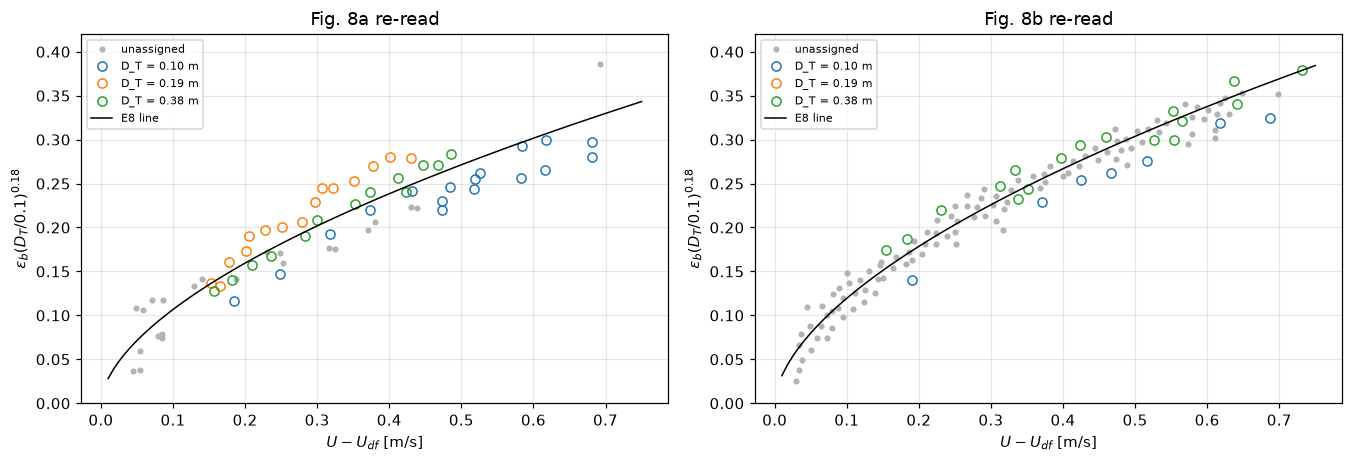

| series | n | A (as plotted) ± SE | A_u = ε_b amplitude |
|---|---|---|---|
| D010_low | 17 | 0.3635 ± 0.0061 | 0.3635 |
| D019_low | 15 | 0.4505 ± 0.0079 | 0.4013 |
| D038_low | 13 | 0.4069 ± 0.0059 | 0.3200 |
| D010_high | 7 | fewer than 8: no amplitude | |
| D038_high | 17 | 0.4688 ± 0.0069 | 0.3686 |

**Diameter (ε_s ≤ 0.10, Fig. 8a).** Relative to 0.10 m, the ε_b amplitude is 1.104 ± 0.027 at 0.19 m and 0.880 ± 0.020 at 0.38 m. N = 0.18 predicts 0.891 and 0.786: the 0.19 m column is +8.8 standard errors from it, the 0.38 m column +5.1. Against no diameter effect (ratio 1) they are +4.1 and -5.7 (these z-scores are marker-level: the marker scatter within one pooled series). As series-level z-scores, with the scatter of the three ε_s series of the 0.10 m reference (log SD 0.062) as the unit, the 0.19 m ratio is +1.4 from 1 and +3.0 from 0.891, the 0.38 m ratio -1.8 from 1 and +1.6 from 0.786. With only the 5 circles of ε_s 0 as reference the ratios are 1.108 and 0.884, so the direction of the 0.19 m and 0.38 m results stands. A formal weighted fit of the three columns gives N = 0.11 (0.02 formal standard error; it is not a fit): its chi-square is 59 on one degree of freedom, so no single power of D_T fits the three columns. Pair by pair the exponent is -0.154 (0.10 to 0.19 m), +0.096 (0.10 to 0.38 m) and +0.327 (0.19 to 0.38 m). The amplitudes are taken at the printed exponent 0.58 over different abscissa ranges; on the range the three series share (0.184 to 0.430 m/s) the same formal fit gives N = 0.30, so a single N depends on the range chosen. The 0.10 m reference pools 2, 7 and 8 markers of ε_s 0, 0.05 and 0.10, and its 0.05 and 0.10 series differ by 11.9 % (4.7 marker standard errors) in one column. Every standard error here is of the marker scatter and holds no run-to-run scatter and no selection. What the figure shows is the order: ε_b at 0.19 m sits higher than at 0.10 m and at 0.38 m lower, which no positive N gives between 0.10 and 0.19 m. 

**Slurry (Fig. 8b against 8a).** At 0.38 m the high-slurry amplitude (ε_s 0.29 and 0.36 pooled) is 1.152 ± 0.024 times the low-slurry one. The paper's own step in α₂ is 1.119, +1.4 marker-level standard errors away (+0.4 series-level), so the figure agrees with the paper's α₂ pair; "virtually independent of slurry concentration" (p. 315) and "the influence on the dilute-phase gas holdup is small" (abstract) are the paper's words for that step. A ratio of exactly 1 is +6.8 marker-level and +1.9 series-level away. These Fig. 8b markers are the ones isolated from the dense band (pluses and crosses at its edges): their amplitude is 4.4 % higher than that of all 99 Fig. 8b markers at U - U_df ≥ 0.15 m/s (11 of 17 lie on the upper side of the drawn line), so part of the ratio can be selection. At 0.10 m only 7 high-slurry markers (circles below the band) carry a label, fewer than the 8 this page requires for an amplitude, so the slurry effect at 0.10 m is not measured here.

In [10]:
def amp(x, y, m):
    v = np.log(y) - m * np.log(x)
    return np.exp(v.mean()), v.std(ddof=1) / np.sqrt(len(v)), len(v)


def study_dilute(p=P, dy8=0.0, pool_a=False):
    out = {}
    xs, ys = {}, {}
    for pan in ("a", "b"):
        k = F8.panel.values == pan
        xs[pan], ys[pan] = to_values(F8[k], CAL[f"fig8{pan}"], dy=dy8)
    fa, fb = F8[F8.panel == "a"], F8[F8.panel == "b"]
    sel = {}
    lowD10 = (fa.D_T.values == "0.10")
    if pool_a:
        lowD10 = fa.U_minus_Udf.values >= 0.15      # labels dropped: every panel-a marker taken as 0.10 m
    sel["D010_low"] = ("a", lowD10)
    sel["D019_low"] = ("a", fa.D_T.values == "0.19")
    sel["D038_low"] = ("a", fa.D_T.values == "0.38")
    sel["D010_high"] = ("b", fb.D_T.values == "0.10")
    sel["D038_high"] = ("b", fb.D_T.values == "0.38")
    A = {}
    for key, (pan, k) in sel.items():
        a_, se, n = amp(xs[pan][k], ys[pan][k], p["m"])
        D = float(key[1:4]) / 100
        A[key] = (a_, se, n, D)
        out[f"fig8_n_{key}"] = n
        out[f"fig8_amp_{key}"] = a_
        out[f"fig8_amp_se_{key}"] = se
    Au = {k: (v[0] * (p["D_ref"] / v[3]) ** p["N"], v[1], v[2], v[3]) for k, v in A.items()}
    for key, D in (("D019_low", 0.19), ("D038_low", 0.38)):
        r = Au[key][0] / Au["D010_low"][0]
        se = np.hypot(Au[key][1], Au["D010_low"][1])
        pred = (D / p["D_ref"]) ** -p["N"]
        out[f"dilute_ratio_{key}"] = r
        out[f"dilute_ratio_se_{key}"] = r * se
        out[f"dilute_ratio_z_vs_N018_{key}"] = np.log(r / pred) / se
        out[f"dilute_ratio_z_vs_N0_{key}"] = np.log(r) / se
    low = ("D010_low", "D019_low", "D038_low")

    def wfit(amps, ses):
        """Weighted fit of ln A_u = c - N ln D_T over the three columns: (N, its formal se, chi-square)."""
        lnD = np.log([A[k][3] for k in low])
        X = np.vstack([np.ones(3), lnD]).T
        w = 1 / np.asarray(ses) ** 2
        cv = np.linalg.inv(X.T @ (w[:, None] * X))
        cf = cv @ X.T @ (w * np.log(amps))
        return -cf[1], np.sqrt(cv[1, 1]), float(np.sum(w * (np.log(amps) - X @ cf) ** 2))

    N_fit, N_se, chi2 = wfit([Au[k][0] for k in low], [Au[k][1] for k in low])
    out["dilute_free_N"] = N_fit
    out["dilute_free_N_se"] = N_se
    out["dilute_free_N_z_vs_018"] = (N_fit - 0.18) / N_se
    out["dilute_free_N_chi2"] = chi2
    r19, r38 = out["dilute_ratio_D019_low"], out["dilute_ratio_D038_low"]
    out["dilute_pair_N_010_019"] = -np.log(r19) / np.log(0.19 / p["D_ref"])
    out["dilute_pair_N_010_038"] = -np.log(r38) / np.log(0.38 / p["D_ref"])
    out["dilute_pair_N_019_038"] = -np.log(r38 / r19) / np.log(0.38 / 0.19)
    # the same fit on the abscissa range the three series share
    lo_x = max(xs["a"][sel[k][1]].min() for k in low)
    hi_x = min(xs["a"][sel[k][1]].max() for k in low)
    out["dilute_shared_range_lo"], out["dilute_shared_range_hi"] = lo_x, hi_x
    win = {}
    for k in low:
        m_ = sel[k][1] & (xs["a"] >= lo_x) & (xs["a"] <= hi_x)
        a_, se_, n_ = amp(xs["a"][m_], ys["a"][m_], p["m"])
        win[k] = (a_ * (p["D_ref"] / A[k][3]) ** p["N"], se_)
    out["dilute_free_N_shared_range"] = wfit([win[k][0] for k in low], [win[k][1] for k in low])[0]
    # series as the unit of scatter: the three eps_s series of the 0.10 m reference
    sub = {}
    for es, tg in (("0", "es0"), ("0.05", "es005"), ("0.10", "es010")):
        k = (fa.D_T.values == "0.10") & (fa.eps_s.values == es)
        sub[es] = amp(xs["a"][k], ys["a"][k], p["m"])
        out[f"fig8_n_D010_{tg}"] = sub[es][2]
    out["dilute_D010_subseries_gap"] = sub["0.10"][0] / sub["0.05"][0] - 1.0
    out["dilute_D010_subseries_z"] = (np.log(sub["0.10"][0] / sub["0.05"][0])
                                      / np.hypot(sub["0.10"][1], sub["0.05"][1]))
    sd = np.std(np.log([v[0] for v in sub.values()]), ddof=1)
    out["dilute_series_logsd_D010"] = sd
    se_ref, se_one = sd / np.sqrt(3), sd
    for key, D in (("D019_low", 0.19), ("D038_low", 0.38)):
        r = out[f"dilute_ratio_{key}"]
        pred = (D / p["D_ref"]) ** -p["N"]
        out[f"dilute_series_z_vs_1_{key}"] = np.log(r) / np.hypot(se_one, se_ref)
        out[f"dilute_series_z_vs_N018_{key}"] = np.log(r / pred) / np.hypot(se_one, se_ref)
    out["N018_factor_D019"] = (0.19 / p["D_ref"]) ** -p["N"]
    out["N018_factor_D038"] = (0.38 / p["D_ref"]) ** -p["N"]
    out["alpha2_ratio"] = p["a2_high"] / p["a2_low"]
    # reference of the circles with eps_s 0 only (labelled, plus the unassigned circles of panel a)
    k0 = ((fa.D_T.values == "0.10") & (fa.eps_s.values == "0")) | (
        (fa.D_T.values == "unassigned") & (fa["shape"].values == "circle"))
    A0 = amp(xs["a"][k0], ys["a"][k0], p["m"])
    out["fig8_n_es0_reference"] = A0[2]
    out["dilute_ratio_D019_es0ref"] = Au["D019_low"][0] / A0[0]
    out["dilute_ratio_D038_es0ref"] = Au["D038_low"][0] / A0[0]
    for D in ("010", "038"):
        r = A[f"D{D}_high"][0] / A[f"D{D}_low"][0]
        se = np.hypot(A[f"D{D}_high"][1], A[f"D{D}_low"][1])
        out[f"slurry_ratio_D{D}"] = r
        out[f"slurry_ratio_se_D{D}"] = r * se
        out[f"slurry_ratio_z_vs_1_D{D}"] = np.log(r) / se
        out[f"slurry_ratio_z_vs_alpha2_D{D}"] = np.log(r / (p["a2_high"] / p["a2_low"])) / se
    se_sl = np.hypot(sd / np.sqrt(2), sd)       # 0.38 m high: two eps_s series, low: one
    out["slurry_series_z_vs_1_D038"] = np.log(out["slurry_ratio_D038"]) / se_sl
    out["slurry_series_z_vs_alpha2_D038"] = np.log(out["slurry_ratio_D038"] / (p["a2_high"] / p["a2_low"])) / se_sl
    # selection: the isolated 0.38 m markers of Fig. 8b against every Fig. 8b marker at U - U_df >= 0.15
    band = fb.U_minus_Udf.values >= 0.15
    a_band, _, n_band = amp(xs["b"][band], ys["b"][band], p["m"])
    out["slurry_selected_over_band_D038"] = A["D038_high"][0] / a_band - 1.0
    out["fig8_n_band_b"] = n_band
    kh = fb.D_T.values == "0.38"
    out["slurry_D038_high_over_line"] = np.log(ys["b"][kh] / (fig8_amplitude(0.36, p) * xs["b"][kh] ** p["m"]))
    out["slurry_D038_high_above_line"] = int((out["slurry_D038_high_over_line"] > 0).sum())
    return out, A


R3, AMP = study_dilute()
small = [k for k, v in AMP.items() if v[2] < 8]      # stop rule: no amplitude from fewer than 8 markers
DROP = {f"fig8_amp_{k}" for k in small} | {f"fig8_amp_se_{k}" for k in small}
if "D010_high" in small:
    DROP |= {k for k in R3 if k.startswith("slurry_ratio") and k.endswith("_D010")}
if small and not set(small) <= {"D010_high"}:
    raise RuntimeError(f"series with fewer than 8 labelled markers: {small}")
for k, v in R3.items():
    if k in DROP:
        continue
    if k.startswith("fig8_n_"):
        claims.exact(k, v, structural=k != "fig8_n_D010_low", note=NOTE_N)
    elif k not in ("slurry_D038_high_over_line", "slurry_D038_high_above_line", "dilute_shared_range_lo",
                 "dilute_shared_range_hi"):      # the range is x data no defect moves: printed, not a claim
        claims.value(k, v, rtol=1e-6)
n_hi = claims.count("slurry_D038_high_above_line", R3["slurry_D038_high_over_line"], 0.0, min_margin=1e-3,
                    relative=False, note="isolated 0.38 m Fig. 8b markers above the drawn line; margin in ln y")
fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.3))
style = {"D010_low": ("C0", "o"), "D019_low": ("C1", "^"), "D038_low": ("C2", "v"), "D010_high": ("C0", "s"), "D038_high": ("C2", "P")}
for pan, axx in (("a", ax[0]), ("b", ax[1])):
    k = F8.panel.values == pan
    x, y = to_values(F8[k], CAL[f"fig8{pan}"])
    lab = F8[k].D_T.values
    axx.plot(x[lab == "unassigned"], y[lab == "unassigned"], ".", color="0.7", label="unassigned")
    for D, col in (("0.10", "C0"), ("0.19", "C1"), ("0.38", "C2")):
        axx.plot(x[lab == D], y[lab == D], "o", mfc="none", color=col, label=f"D_T = {D} m")
    xx = np.linspace(0.01, 0.75, 100)
    axx.plot(xx, fig8_amplitude(0.0 if pan == "a" else 0.36, P) * xx ** 0.58, "k-", lw=1, label="E8 line")
    axx.set(xlabel=r"$U - U_{df}$ [m/s]", ylabel=r"$\epsilon_b (D_T/0.1)^{0.18}$", ylim=(0, 0.42),
            title=f"Fig. 8{pan} re-read")
    axx.legend(fontsize=7)
fig.tight_layout(); plt.show()
md("| series | n | A (as plotted) ± SE | A_u = ε_b amplitude |\n|---|---|---|---|\n" + "\n".join(
    (f"| {k} | {v[2]} | {v[0]:.4f} ± {v[0] * v[1]:.4f} | {v[0] * (0.1 / v[3]) ** 0.18:.4f} |" if v[2] >= 8
     else f"| {k} | {v[2]} | fewer than 8: no amplitude | |") for k, v in AMP.items()))
md(f"**Diameter (ε_s ≤ 0.10, Fig. 8a).** Relative to 0.10 m, the ε_b amplitude is "
   f"{R3['dilute_ratio_D019_low']:.3f} ± {R3['dilute_ratio_se_D019_low']:.3f} at 0.19 m and "
   f"{R3['dilute_ratio_D038_low']:.3f} ± {R3['dilute_ratio_se_D038_low']:.3f} at 0.38 m. N = 0.18 predicts "
   f"{computed['diameter_factor_019']:.3f} and {computed['diameter_factor_038']:.3f}: the 0.19 m column is "
   f"{R3['dilute_ratio_z_vs_N018_D019_low']:+.1f} standard errors from it, the 0.38 m column "
   f"{R3['dilute_ratio_z_vs_N018_D038_low']:+.1f}. Against no diameter effect (ratio 1) they are "
   f"{R3['dilute_ratio_z_vs_N0_D019_low']:+.1f} and {R3['dilute_ratio_z_vs_N0_D038_low']:+.1f} (these z-scores are "
   f"marker-level: the marker scatter within one pooled series). As series-level z-scores, with the scatter of the "
   f"three ε_s series of the 0.10 m reference (log SD {R3['dilute_series_logsd_D010']:.3f}) as the unit, the 0.19 m "
   f"ratio is {R3['dilute_series_z_vs_1_D019_low']:+.1f} from 1 and {R3['dilute_series_z_vs_N018_D019_low']:+.1f} "
   f"from {computed['diameter_factor_019']:.3f}, the 0.38 m ratio {R3['dilute_series_z_vs_1_D038_low']:+.1f} from 1 "
   f"and {R3['dilute_series_z_vs_N018_D038_low']:+.1f} from {computed['diameter_factor_038']:.3f}. With only the "
   f"{R3['fig8_n_es0_reference']} circles of ε_s 0 as reference the ratios are {R3['dilute_ratio_D019_es0ref']:.3f} "
   f"and {R3['dilute_ratio_D038_es0ref']:.3f}, so the direction of the 0.19 m and 0.38 m results stands. A formal "
   f"weighted fit of the three columns gives N = {R3['dilute_free_N']:.2f} ({R3['dilute_free_N_se']:.2f} formal "
   f"standard error; it is not a fit): its chi-square is {R3['dilute_free_N_chi2']:.0f} on one degree of freedom, "
   f"so no single power of D_T fits the three columns. Pair by pair the exponent is "
   f"{R3['dilute_pair_N_010_019']:+.3f} (0.10 to 0.19 m), {R3['dilute_pair_N_010_038']:+.3f} (0.10 to 0.38 m) and "
   f"{R3['dilute_pair_N_019_038']:+.3f} (0.19 to 0.38 m). The amplitudes are taken at the printed exponent 0.58 "
   f"over different abscissa ranges; on the range the three series share "
   f"({R3['dilute_shared_range_lo']:.3f} to {R3['dilute_shared_range_hi']:.3f} m/s) the same formal fit gives "
   f"N = {R3['dilute_free_N_shared_range']:.2f}, so a single N depends on the range chosen. The 0.10 m reference "
   f"pools {R3['fig8_n_D010_es0']}, {R3['fig8_n_D010_es005']} and {R3['fig8_n_D010_es010']} markers of ε_s 0, "
   f"0.05 and 0.10, and its 0.05 and 0.10 series differ by {R3['dilute_D010_subseries_gap'] * 100:.1f} % "
   f"({R3['dilute_D010_subseries_z']:.1f} marker standard errors) in one column. Every standard error here is "
   f"of the marker scatter and holds no run-to-run scatter and no selection. "
   + (f"What the figure shows is the order: ε_b at 0.19 m sits higher than at 0.10 m and at 0.38 m lower, which "
      f"no positive N gives between 0.10 and 0.19 m. "
      if R3['dilute_pair_N_010_019'] < 0 < R3['dilute_pair_N_010_038'] else "")
   + "\n\n"
   f"**Slurry (Fig. 8b against 8a).** At 0.38 m the high-slurry amplitude (ε_s 0.29 and 0.36 pooled) is "
   f"{R3['slurry_ratio_D038']:.3f} ± {R3['slurry_ratio_se_D038']:.3f} times the low-slurry one. The paper's own "
   f"step in α₂ is {R3['alpha2_ratio']:.3f}, {R3['slurry_ratio_z_vs_alpha2_D038']:+.1f} marker-level standard "
   f"errors away ({R3['slurry_series_z_vs_alpha2_D038']:+.1f} series-level), so the figure agrees with the paper's "
   f"α₂ pair; \"virtually independent of slurry concentration\" (p. 315) and \"the influence on the dilute-phase "
   f"gas holdup is small\" (abstract) are the paper's words for that step. A ratio of exactly 1 is "
   f"{R3['slurry_ratio_z_vs_1_D038']:+.1f} marker-level and {R3['slurry_series_z_vs_1_D038']:+.1f} series-level "
   f"away. These Fig. 8b markers are the ones isolated from the dense band (pluses and crosses at its edges): "
   f"their amplitude is {R3['slurry_selected_over_band_D038'] * 100:.1f} % higher than that of all "
   f"{R3['fig8_n_band_b']} Fig. 8b markers at U - U_df ≥ 0.15 m/s ({n_hi} of {len(R3['slurry_D038_high_over_line'])} "
   f"lie on the upper side of the drawn line), so part of the ratio can be selection. At 0.10 m only {AMP['D010_high'][2]} high-slurry markers (circles below "
   f"the band) carry a label, fewer than the 8 this page requires for an amplitude, so the slurry effect at 0.10 m "
   f"is not measured here.")

### R4. Total holdup: eqs. 2 to 7 against the Fig. 9 markers

Each Fig. 9 marker is assigned to the nearest of the three drawn curves; markers with
$U > 2U_{df}$ (the cut `F2.3` uses) are compared. Mean absolute deviation and mean bias
with its standard error, then one ingredient changed at a time.

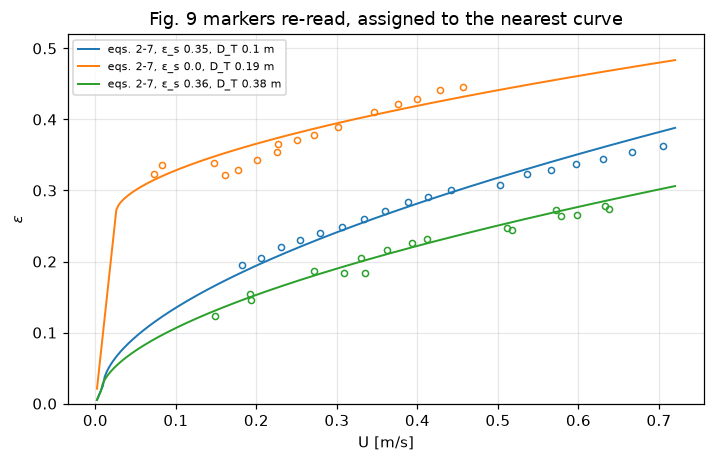

| set | n | mean abs. dev. | bias ± SE |
|---|---|---|---|
| ε_s 0.35, 0.1 m | 18 | 3.4 % | -0.2 ± 0.9 % |
| ε_s 0.0, 0.19 m | 16 | 3.8 % | +1.4 ± 1.1 % |
| ε_s 0.36, 0.38 m | 17 | 3.7 % | +1.6 ± 1.0 % |

For the 0.38 m set at ε_s = 0.36, replacing eq. 4's 0.018 by the Fig. 6 mean 0.0130 changes the mean absolute deviation from 3.7 % to 3.4 % (bias -0.0 %); α₂ = 0.268 instead of 0.3 gives 8.3 % (bias -8.3 %). `F2.3`, on a different figure (Maretto and Krishna 1999, 0.10 m, ε_s = 0.35), reports 4.9 % mean absolute deviation and -3.7 % bias, beside this page's 3.4 % and -0.2 % for the 0.10 m set of Fig. 9.

In [11]:
SETS9 = ((0.35, 0.10), (0.0, 0.19), (0.36, 0.38))


def study_total(p=P, dy9=0.0, overlap=True, udf_form="paper", edf036=None, a2_036=None):
    out = {}
    U, e = to_values(F9, CAL["fig9"], dy=dy9)
    curves = np.array([eps_total(U, D, es, P) for es, D in SETS9])
    near = np.argmin(np.abs(curves - e), axis=0)
    for i, (es, D) in enumerate(SETS9):
        q = dict(p)
        k = (near == i) & (U > 2 * float(u_df(es, P)))
        if es == 0.36 and edf036 is not None:
            q["edf0"] = edf036 + q["cE"] * 0.36
        if es == 0.36 and a2_036 is not None:
            q["a2_high"] = a2_036
        dev = eps_total(U[k], D, es, q, overlap=overlap, udf_form=udf_form) / e[k] - 1
        tag = TAG[es]
        out[f"fig9_n_es{tag}"] = int(k.sum())
        out[f"fig9_mad_es{tag}"] = np.abs(dev).mean()
        out[f"fig9_bias_es{tag}"] = dev.mean()
        out[f"fig9_bias_se_es{tag}"] = dev.std(ddof=1) / np.sqrt(k.sum())
    return out


R4 = study_total()
for k, v in R4.items():
    if k.startswith("fig9_n_"):
        claims.exact(k, v, structural=True, note="markers above 2 U_df nearest each curve; measured unchanged under every row")
    else:
        claims.value(k, v, rtol=1e-6)
R4e = study_total(edf036=R2["fig6_mean_es036"])
R4a = study_total(a2_036=P["a2_low"])
claims.value("fig9_mad_es036_fig6_edf", R4e["fig9_mad_es036"], rtol=1e-6)
claims.value("fig9_bias_es036_fig6_edf", R4e["fig9_bias_es036"], rtol=1e-6)
claims.value("fig9_mad_es036_alpha2_0268", R4a["fig9_mad_es036"], rtol=1e-6)
claims.value("fig9_bias_es036_alpha2_0268", R4a["fig9_bias_es036"], rtol=1e-6)
F23 = load_claims("F2.3-slurry-bubble-column-ft")
U9, e9 = to_values(F9, CAL["fig9"])
fig, ax = plt.subplots(figsize=(6.6, 4.3))
for i, (es, D) in enumerate(SETS9):
    UU = np.linspace(0.002, 0.72, 300)
    l, = ax.plot(UU, eps_total(UU, D, es, P), lw=1.3, label=f"eqs. 2-7, ε_s {es}, D_T {D} m")
    curves = np.array([eps_total(U9, DD, ee, P) for ee, DD in SETS9])
    k = np.argmin(np.abs(curves - e9), axis=0) == i
    ax.plot(U9[k], e9[k], "o", mfc="none", color=l.get_color(), ms=4)
ax.set(xlabel="U [m/s]", ylabel=r"$\epsilon$", title="Fig. 9 markers re-read, assigned to the nearest curve", ylim=(0, 0.52))
ax.legend(fontsize=7); fig.tight_layout(); plt.show()
md("| set | n | mean abs. dev. | bias ± SE |\n|---|---|---|---|\n" + "\n".join(
    f"| ε_s {es}, {D} m | {R4[f'fig9_n_es{TAG[es]}']} | {R4[f'fig9_mad_es{TAG[es]}'] * 100:.1f} % | "
    f"{R4[f'fig9_bias_es{TAG[es]}'] * 100:+.1f} ± {R4[f'fig9_bias_se_es{TAG[es]}'] * 100:.1f} % |" for es, D in SETS9))
md(f"For the 0.38 m set at ε_s = 0.36, replacing eq. 4's {float(eps_df(0.36, P)):.3f} by the Fig. 6 mean "
   f"{R2['fig6_mean_es036']:.4f} changes the mean absolute deviation from {R4['fig9_mad_es036'] * 100:.1f} % to "
   f"{R4e['fig9_mad_es036'] * 100:.1f} % (bias {R4e['fig9_bias_es036'] * 100:+.1f} %); α₂ = 0.268 instead of 0.3 "
   f"gives {R4a['fig9_mad_es036'] * 100:.1f} % (bias {R4a['fig9_bias_es036'] * 100:+.1f} %). `F2.3`, on a "
   f"different figure (Maretto and Krishna 1999, 0.10 m, ε_s = 0.35), reports "
   f"{F23['holdup_mad_eps_s_035'] * 100:.1f} % mean absolute deviation and {F23['holdup_bias_eps_s_035'] * 100:+.1f} % "
   f"bias, beside this page's {R4['fig9_mad_es035'] * 100:.1f} % and {R4['fig9_bias_es035'] * 100:+.1f} % for the "
   f"0.10 m set of Fig. 9.")

### R5. What the split, as the correlations encode it, does to a reactor

Closed forms of the page's reactor at $D_T = 0.38$ m. The numbers are consequences of
the printed correlations with a rate constant of the page's choosing, never
measurements: no conversion was measured in the paper.

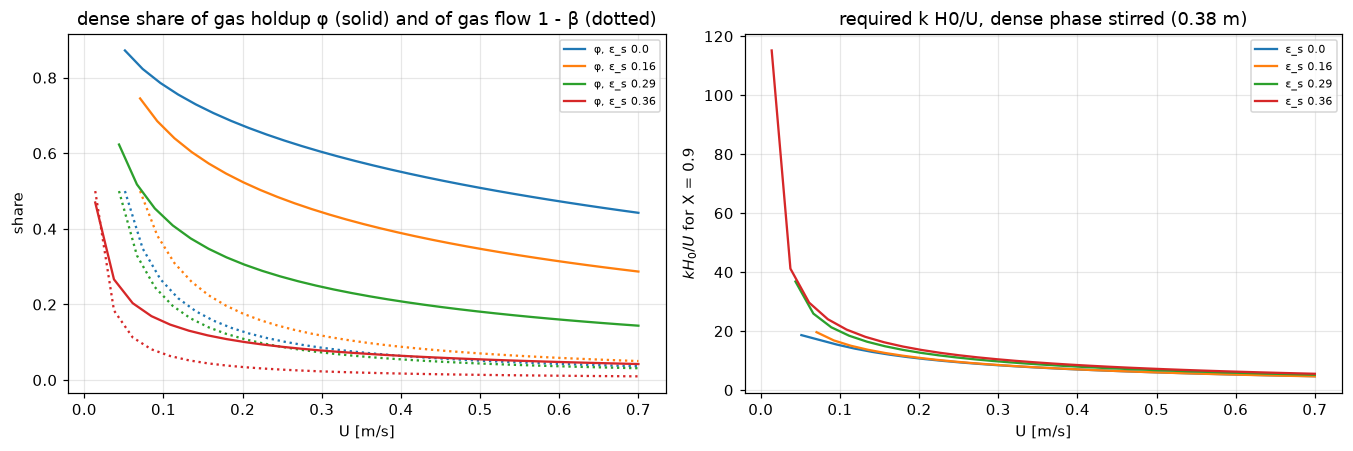

At U = 0.30 m/s in the 0.38 m column the correlations give ε = 0.380 without solids and 0.190 at ε_s = 0.36: the slurry divides the holdup by 2.00. At low conversion the reactor's capacity scales with ε/(1 - ε), which drops 2.61-fold. At X = 0.9 with the dense phase stirred, the required k H₀/U rises only 1.236-fold (8.42 to 10.41). The reason is the split: without solids 60 % of the gas holdup is stirred dense phase carrying 8.6 % of the flow, so most of the holdup the slurry removes held gas that was already converted, and the large bubbles, which carry the flow, keep their holdup (ε_b 0.151 to 0.175). How the dense phase is mixed hardly matters: stirred instead of plug flow raises the required D by 1.0 % without solids and 1.1 % at ε_s = 0.36; over the Péclet band 1 to 100 D runs from 5.107 to 5.105 at ε_s = 0. Two sensitivities of the ratio 1.236: with the Fig. 6 mean dense-phase voidage (0.0130 instead of eq. 4's 0.018) it is 1.2447; with the dense-phase gas reacting 2 times faster per unit volume (a chosen value) it is 1.2363, against 1.2363. Per unit of gas, the plug-flow large bubbles convert more than the stirred dense phase once k τ_b exceeds 4.252 (ε_s = 0) or 2.181 (ε_s = 0.36), the one crossing found by `find_roots` and by Lambert W.

In [12]:
def study_reactor(p=P, udf_form="paper", overlap_in_tau=True, H_is_H0=False, k_ratio=1.0):
    kw = dict(udf_form=udf_form, overlap_in_tau=overlap_in_tau)
    out = {}
    for sfx, c in (("T", T), ("T0", T0)):
        s = case(c, p, **kw)
        Ds = d_required(s, X_TARGET, "stirred", k_ratio=k_ratio)
        Dp = d_required(s, X_TARGET, "plug", k_ratio=k_ratio)
        Dd = d_required(s, X_TARGET, "dispersed", PE_REF, k_ratio=k_ratio)
        kk = (lambda D: D / s["eps"]) if H_is_H0 else (lambda D: kH0_over_U(D, s))
        out.update({f"eps_{sfx}": s["eps"], f"beta_{sfx}": s["beta"], f"phi_{sfx}": s["phi"],
                    f"tb_{sfx}": s["tb"], f"tdf_{sfx}": s["tdf"], f"D_stirred_{sfx}": Ds, f"D_plug_{sfx}": Dp,
                    f"D_disp_{sfx}": Dd, f"k_stirred_{sfx}": kk(Ds), f"k_plug_{sfx}": kk(Dp),
                    f"k_disp_{sfx}": kk(Dd), f"mixing_effect_{sfx}": Ds / Dp - 1,
                    f"dense_share_{sfx}": (1 - s["beta"]) * x_dense(k_ratio * Ds * s["tdf"], "stirred") / X_TARGET,
                    f"cross_a_{sfx}": crossing(s), f"cross_a_roots_{sfx}": crossing(s, "roots")})
        out[f"D_disp_Pe1_{sfx}"] = d_required(s, X_TARGET, "dispersed", 1.0, k_ratio=k_ratio)
        out[f"D_disp_Pe100_{sfx}"] = d_required(s, X_TARGET, "dispersed", 100.0, k_ratio=k_ratio)
    out["eps_ratio_T0_T"] = out["eps_T0"] / out["eps_T"]
    out["capacity_ratio_k0"] = (out["eps_T0"] / (1 - out["eps_T0"])) / (out["eps_T"] / (1 - out["eps_T"]))
    out["k_ratio_T_T0_stirred"] = out["k_stirred_T"] / out["k_stirred_T0"]
    return out


R5 = study_reactor()
SKIP5 = {"cross_a_roots_T", "cross_a_roots_T0"}
for k, v in R5.items():
    if k not in SKIP5:
        claims.value(k, v, rtol=1e-6)
for sfx in ("T", "T0"):
    claims.bound(f"crossing_two_routes_{sfx}", abs(R5[f"cross_a_{sfx}"] - R5[f"cross_a_roots_{sfx}"]), max=1e-9,
                 basis="tolerance", structural=True, note="Lambert W against find_roots, xtol 1e-12; an identity of R7")
# measured dense-phase voidage (Fig. 6, 0.38 m) instead of eq. 4 at 0.36, and k_df/k_b = 2
K_RATIO = 2.0   # chosen sensitivity: dense-phase gas reacting twice as fast per unit gas volume
sTm = split(T["U"], T["D_T"], 0.36, P, H0=H0[(0.38, 0.36)], edf=R2["fig6_mean_es036"])
r_meas = kH0_over_U(d_required(sTm), sTm) / R5["k_stirred_T0"]
R5k = study_reactor(k_ratio=K_RATIO)
claims.value("k_ratio_T_T0_fig6_edf", r_meas, rtol=1e-6)
claims.value("k_ratio_T_T0_kratio2", R5k["k_ratio_T_T0_stirred"], rtol=1e-6)
# figure: over U from 2 U_df to 0.7 m/s at the four 0.38 m concentrations
fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.2))
for es in (0.0, 0.16, 0.29, 0.36):
    UU = np.linspace(2 * float(u_df(es, P)), 0.7, 30)
    ss = [split(u, 0.38, es, P, H0=H0[(0.38, es)]) for u in UU]
    l, = ax[0].plot(UU, [s["phi"] for s in ss], label=f"φ, ε_s {es}")
    ax[0].plot(UU, [1 - s["beta"] for s in ss], ":", color=l.get_color())
    ax[1].plot(UU, [kH0_over_U(d_required(s), s) for s in ss], color=l.get_color(), label=f"ε_s {es}")
ax[0].set(xlabel="U [m/s]", ylabel="share", title="dense share of gas holdup φ (solid) and of gas flow 1 - β (dotted)")
ax[0].legend(fontsize=7)
ax[1].set(xlabel="U [m/s]", ylabel=r"$k H_0/U$ for X = 0.9", title="required k H0/U, dense phase stirred (0.38 m)")
ax[1].legend(fontsize=7); fig.tight_layout(); plt.show()
md(f"At U = 0.30 m/s in the 0.38 m column the correlations give ε = {R5['eps_T0']:.3f} without solids and "
   f"{R5['eps_T']:.3f} at ε_s = 0.36: the slurry divides the holdup by {R5['eps_ratio_T0_T']:.2f}. At low "
   f"conversion the reactor's capacity scales with ε/(1 - ε), which drops "
   f"{R5['capacity_ratio_k0']:.2f}-fold. At X = 0.9 with the dense phase stirred, the required k H₀/U rises "
   f"only {R5['k_ratio_T_T0_stirred']:.3f}-fold ({R5['k_stirred_T0']:.2f} to {R5['k_stirred_T']:.2f}). The "
   f"reason is the split: without solids {R5['phi_T0'] * 100:.0f} % of the gas holdup is stirred dense phase "
   f"carrying {(1 - R5['beta_T0']) * 100:.1f} % of the flow, so most of the holdup the slurry removes held gas "
   f"that was already converted, and the large bubbles, which carry the flow, keep their holdup "
   f"(ε_b {computed['eps_b_T0']:.3f} to {computed['eps_b_T']:.3f}). How the dense phase is mixed hardly "
   f"matters: stirred instead of plug flow raises the required D by {R5['mixing_effect_T0'] * 100:.1f} % "
   f"without solids and {R5['mixing_effect_T'] * 100:.1f} % at ε_s = 0.36; over the Péclet band 1 to 100 "
   f"D runs from {R5['D_disp_Pe1_T0']:.3f} to {R5['D_disp_Pe100_T0']:.3f} at ε_s = 0. Two sensitivities of "
   f"the ratio {R5['k_ratio_T_T0_stirred']:.3f}: with the Fig. 6 mean dense-phase voidage "
   f"({R2['fig6_mean_es036']:.4f} instead of eq. 4's {float(eps_df(0.36, P)):.3f}) it is {r_meas:.4f}; with "
   f"the dense-phase gas reacting {K_RATIO:g} times faster per unit volume (a chosen value) it is "
   f"{R5k['k_ratio_T_T0_stirred']:.4f}, against {R5['k_ratio_T_T0_stirred']:.4f}. Per unit of gas, the plug-flow large bubbles convert more than the "
   f"stirred dense phase once k τ_b exceeds {R5['cross_a_T0']:.3f} (ε_s = 0) or {R5['cross_a_T']:.3f} "
   f"(ε_s = 0.36), the one crossing found by `find_roots` and by Lambert W.")

## Validation

**V1. Identities** (structural: no defect can move them). Eq. 1 inverts eq. 7; eq. 3
meets eq. 7 at $U_{df}$ (eq. 5 makes $U_{df}/V_{small} = \varepsilon_{df}$); the
residence times satisfy $\beta\tau_b + (1-\beta)\tau_{df} = \tau$; the Danckwerts form
reduces to the stirred and plug forms at Pe 1e-6 and 1e5.

In [13]:
claims.bound("v1_eq1_inverts_eq7", abs(computed["eq1_inverts_eq7_T"] - 1), max=1e-14, basis="identity", structural=True)
claims.bound("v1_eq3_meets_eq7", abs(computed["eq3_eq7_continuity_T"] - 1), max=1e-14, basis="identity", structural=True)
claims.bound("v1_rtd_identity", max(abs(computed["rtd_identity_T"] - 1), abs(computed["rtd_identity_T0"] - 1)),
             max=1e-14, basis="identity", structural=True)
Da0 = RT0["D_dispersed"] * s0["tdf"]
g_lo = abs(x_dense(Da0, "dispersed", 1e-6) / x_dense(Da0, "stirred") - 1)
g_hi = abs(x_dense(Da0, "dispersed", 1e5) / x_dense(Da0, "plug") - 1)
claims.bound("v1_dispersed_to_stirred_Pe1e-6", g_lo, max=1e-5, basis="theory", structural=True,
             note="the dispersed form differs from the stirred one by O(Pe Da)")
claims.bound("v1_dispersed_to_plug_Pe1e5", g_hi, max=1e-3, basis="theory", structural=True,
             note="the dispersed form differs from plug flow by O(Da^2/Pe)")
print(f"identities: eq. 1 vs eq. 7 below 1e-14, eq. 3 vs eq. 7 below 1e-14, RTD below 1e-14; "
      f"Danckwerts limits below 1e-5 (here {g_lo:.1e}) and below 1e-3 (here {g_hi:.1e})")

identities: eq. 1 vs eq. 7 below 1e-14, eq. 3 vs eq. 7 below 1e-14, RTD below 1e-14; Danckwerts limits below 1e-5 (here 1.6e-07) and below 1e-3 (here 0.0e+00)


**V2. The pymrm solve.** At T0 and T, Pe = 5, at the closed-form design root, on the
ladder n = 50 × 2^k (k = 0 to 5). Observed orders of both exit face values and of X
(theory 1: first-order upwind), the Richardson value of X against the target 0.9, the
large-bubble exit against $e^{-D\tau_b/\tau}$, and a round-off companion: the finest grid
solved again with a second column ordering (`permc_spec="MMD_AT_PLUS_A"`), its
difference at least 100 times below the finest grid difference.

In [14]:
NS = [50 * 2 ** k for k in range(6)]


def study_fv(b_outlet="outflow", inlet_sign=1.0, cell_pe=False, companion="ordering", root="dispersed"):
    out = {}
    for sfx, R in (("T", RT), ("T0", RT0)):
        s = R["s"]
        D = R["D_dispersed"]
        Ds = R[f"D_{root}"]          # the root the solve is run at (a defect when not the dispersed one)

        def solve(n, kw=None):
            pe = PE_REF * n / NS[0] if cell_pe else PE_REF
            m = TwoClassReactor(n, pe, Ds * s["tb"], Ds * s["tdf"], s["beta"], b_outlet, inlet_sign).solve(kw)
            return np.array([*m.exits(), m.conversion()])
        st = observed_orders(solve, NS)
        o = np.asarray(st["orders"])
        out[f"fv_order_min_{sfx}"], out[f"fv_order_max_{sfx}"] = o.min(), o.max()
        out[f"fv_X_extrap_gap_{sfx}"] = abs(st["extrapolated"][2] / X_TARGET - 1)
        out[f"fv_b_exit_extrap_gap_{sfx}"] = abs(st["extrapolated"][0] / np.exp(-D * s["tb"]) - 1)
        fine = np.asarray(st["values"][-1]); prev = np.asarray(st["values"][-2])
        other = solve(NS[-1], {"permc_spec": "MMD_AT_PLUS_A"}) if companion == "ordering" else prev
        out[f"fv_finest_over_roundoff_{sfx}"] = np.abs(fine - prev).min() / max(np.abs(fine - other).max(), 1e-300)
        out[f"fv_X_finest_{sfx}"] = fine[2]
    return out


V2 = study_fv()
for sfx in ("T", "T0"):
    for mm in ("min", "max"):
        o = V2[f"fv_order_{mm}_{sfx}"]
        if not 0.8 <= o <= 1.2:      # plan stop rule: drop the FV curve, the closed forms stand
            raise RuntimeError(f"observed order {o} is off first order by more than 0.2")
        claims.value(f"fv_order_{mm}_{sfx}", o, rtol=1e-4,
                     note="first-order upwind (theory 1, stop rule 0.8 to 1.2); over exits and X, ladder 50 to 1600")
    claims.bound(f"fv_X_extrap_gap_{sfx}", V2[f"fv_X_extrap_gap_{sfx}"], max=1e-4, basis="theory",
                 note="Richardson limit of a first-order sequence against the closed form")
    claims.bound(f"fv_b_exit_extrap_gap_{sfx}", V2[f"fv_b_exit_extrap_gap_{sfx}"], max=1e-4, basis="theory")
    claims.bound(f"fv_finest_over_roundoff_{sfx}", V2[f"fv_finest_over_roundoff_{sfx}"], min=100.0, basis="chosen",
                 note="finest grid difference against a second column ordering at the finest grid")
    claims.value(f"fv_X_finest_{sfx}", V2[f"fv_X_finest_{sfx}"], rtol=1e-8)
md(f"Orders {V2['fv_order_min_T0']:.3f} to {V2['fv_order_max_T0']:.3f} at T0 and {V2['fv_order_min_T']:.3f} to "
   f"{V2['fv_order_max_T']:.3f} at T (theory 1); the Richardson value of X is within 1e-4 of 0.9 (here "
   f"{V2['fv_X_extrap_gap_T0']:.1e} and {V2['fv_X_extrap_gap_T']:.1e}); the large-bubble exit within 1e-4 of "
   f"exp(-D τ_b/τ) (here {V2['fv_b_exit_extrap_gap_T0']:.1e} and {V2['fv_b_exit_extrap_gap_T']:.1e}); the finest "
   f"grid difference is at least 100 times the change from a second ordering (the ratio itself is round-off "
   f"and differs between BLAS kernels).")

Orders 0.994 to 0.999 at T0 and 0.995 to 0.999 at T (theory 1); the Richardson value of X is within 1e-4 of 0.9 (here 1.1e-07 and 1.0e-07); the large-bubble exit within 1e-4 of exp(-D τ_b/τ) (here 9.7e-07 and 9.0e-07); the finest grid difference is at least 100 times the change from a second ordering (the ratio itself is round-off and differs between BLAS kernels).

**V3** is the check-value cell above (every row reproduced within its rtol). **V4**:
tick residuals below 2 px and the Fig. 6 second pass are claims in the data cell.

### The break table

Each row injects one defect through an argument and recomputes every number of the
studies it touches; a row catches a claim when the claim's own check fails.

In [15]:
record(ROWS[0], {"k_ratio_T_T0_kratio2": study_reactor(with_(a2_high=P["a2_low"]), k_ratio=K_RATIO)["k_ratio_T_T0_stirred"],
                 **study_lines(with_(a2_high=P["a2_low"])), **study_total(with_(a2_high=P["a2_low"])),
                 **study_reactor(with_(a2_high=P["a2_low"])), **study_dilute(with_(a2_high=P["a2_low"]))[0]})
record(ROWS[1], study_lines(D_ref=1.0))
record(ROWS[2], {**study_dilute(with_(N=0.0))[0], **study_reactor(with_(N=0.0)), **study_lines(with_(N=0.0)),
                 **study_total(with_(N=0.0))})
record(ROWS[3], {**study_total(overlap=False)})
record(ROWS[4], {**study_total(udf_form="reilly"), **study_reactor(udf_form="reilly")})
q = with_(V0=0.0794)
sq = split(T["U"], T["D_T"], 0.36, q, H0=H0[(0.38, 0.36)], edf=R2["fig6_mean_es036"])
record(ROWS[5], {**study_fig5(q), **study_total(q), **study_reactor(q), "udf_max_eps_s": udf_maximum(q)[0],
                 "udf_max": udf_maximum(q)[1],
                 "k_ratio_T_T0_fig6_edf": kH0_over_U(d_required(sq), sq) / study_reactor(q)["k_stirred_T0"]})
q = with_(cE=0.72)
r_ = study_total(q, edf036=R2["fig6_mean_es036"])
record(ROWS[6], {**study_dense(q), **study_lines(q), **study_reactor(q), "udf_max_eps_s": udf_maximum(q)[0],
                 "udf_max": udf_maximum(q)[1], "fig9_mad_es036_fig6_edf": r_["fig9_mad_es036"],
                 "fig9_bias_es036_fig6_edf": r_["fig9_bias_es036"],
                 "fig9_mad_es036_alpha2_0268": study_total(q, a2_036=P["a2_low"])["fig9_mad_es036"],
                 "fig9_bias_es036_alpha2_0268": study_total(q, a2_036=P["a2_low"])["fig9_bias_es036"],
                 **study_total(q)})
q = with_(edf0=0.25)
record("eps_df,0 = 0.25", {**study_dense(q), **study_lines(q), **study_reactor(q), **study_total(q)})
record(ROWS[8], study_reactor(overlap_in_tau=False))
record(ROWS[9], study_reactor(H_is_H0=True))
record(ROWS[10], study_fig5(x0_px=273.0))
d9 = study_total(dy9=3.0)
d9e, d9a = study_total(dy9=3.0, edf036=study_dense(dy6=3.0)["fig6_mean_es036"]), study_total(dy9=3.0, a2_036=P["a2_low"])
record(ROWS[11], {**study_dense(dy6=3.0), **d9, **study_lines(dy7=3.0, dy9=3.0), "fig9_mad_es036_fig6_edf": d9e["fig9_mad_es036"],
                  "fig9_bias_es036_fig6_edf": d9e["fig9_bias_es036"], "fig9_mad_es036_alpha2_0268": d9a["fig9_mad_es036"],
                  "fig9_bias_es036_alpha2_0268": d9a["fig9_bias_es036"]})
record(ROWS[12], study_dense(legend=True))
record(ROWS[13], study_dense(glyph=False))
record(ROWS[14], study_dense(err7=0.015))
record(ROWS[15], study_dense(u_min=0.2))
record(ROWS[16], study_fv(root="stirred"))
record(ROWS[17], study_dense(swap016=True))
record(ROWS[18], {**study_dilute(dy8=3.0)[0], **study_lines(dy8=3.0)})
record(ROWS[19], study_dilute(pool_a=True)[0])
record(ROWS[20], study_fv(b_outlet="zero_gradient"))
record(ROWS[21], study_fv(inlet_sign=-1.0))
record(ROWS[22], study_fv(cell_pe=True))
record(ROWS[23], study_fv(companion="coarser"))
caught_rows = {r for r, _, _, _, c in BREAK if c}
print(f"{len(ROWS)} rows defined; rows that catch no claim: "
      f"{[r for r in ROWS if r not in caught_rows] or 'none'}")
for row in ROWS:
    hits = [(k, v0, v1) for r, k, v0, v1, c in BREAK if r == row and c]
    if hits:
        vh = [h for h in hits if claims.metrics[h[0]]["kind"] != "bound"]
        k, v0, v1 = (vh or hits)[0]
        shown = f"{v0:.5g} -> {v1:.5g}" if vh else f"breaks its bound {v1:.1e}"
        print(f"  {row:60s} catches {len(hits):3d} claims, e.g. {k}: {shown}")

24 rows defined; rows that catch no claim: none
  alpha2 0.268 for eps_s >= 0.16                               catches  34 claims, e.g. k_ratio_T_T0_kratio2: 1.2363 -> 1.4143
  D_ref ignored in the Fig. 8 line amplitude                   catches   2 claims, e.g. fig8a_line_gap_E8: -0.003452 -> 0.50834
  N = 0 in eq. 6                                               catches  67 claims, e.g. dilute_ratio_D019_low: 1.1039 -> 1.2391
  eq. 7 without the (1 - eps_b) overlap                        catches   9 claims, e.g. fig9_mad_es035: 0.034104 -> 0.033452
  U_df in the Reilly form V eps_df (1 - eps_df)                catches  44 claims, e.g. fig9_mad_es035: 0.034104 -> 0.033931
  V_small,0 = 0.0794 (the Fig. 5 line)                         catches  54 claims, e.g. fig5_gap_eq2_es0: -0.16559 -> -0.0016505
  eq. 4 slope 0.72                                             catches  51 claims, e.g. fig6_minus_eq4_es016: -0.034245 -> -0.031045
  eps_df,0 = 0.25                                        

## What pymrm adds

Nothing in R1 to R4: they are algebra on figure reads, and the correlations need no
solver. In R5 every number has a closed form. pymrm contributes `find_roots` (every
design root, the per-gas crossing and the maximum of $U_{df}$, each raised on unless
exactly one root exists in the physical range) and the assembled two-class reactor:
upwind plug flow for the large bubbles with an outflow outlet and convection-dispersion
with a Danckwerts inlet for the dense phase, one linear `newton` step, exit values from
`compute_boundary_values`, converging at first order to the closed form (`observed_orders`,
with a round-off companion). `F2.3` builds the same two-class structure with liquid
coupling and kinetics.

## Reuse

- To apply the correlations to another column: change `T`; outside 0.10 to 0.38 m,
  paraffin oil and silica they are untested, and between ε_s 0.10 and 0.16 `alpha2`
  raises on purpose.
- To test them on other data: the `study_*` functions take a parameter dictionary and
  pixel reads with a sidecar calibration; a new figure needs only a CSV of that form.
- The reactor: `split` gives β, φ and the residence-time ratios; `conversion` and
  `d_required` take any dense-phase mixing model; `TwoClassReactor` is the pymrm form
  to extend with exchange between the classes or a liquid phase (as `F2.3` does).
- Related pages: `F1.4` (eq. 6's origin in gas-liquid columns), `F2.3` (the
  Fischer-Tropsch reactor on the same correlations), `F2.1` (axial dispersion in bubble
  columns), `A2.1` (the Danckwerts vessel), `E1.1` (two-phase theory of fluidised beds).

In [16]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F2.2:
  tick_residual_worst_px                 = (here 1.0e+00)   bound  bound <= 2 [chosen]
  second_pass_fig6_max_diff              = (here 3.9e-04)   bound  bound <= 0.002 [chosen]
  check_values_agree                     = 101              exact  exact
  fig6_markers                           = 97               exact  exact
  fig9_markers                           = 51               exact  exact
  fig8_markers                           = 199              exact  exact
  fig5_V_small_es0                       = 0.079269         value  rtol 1e-06
  fig5_gap_eq2_es0                       = -0.16559         value  rtol 1e-06
  fig5_V_small_es005                     = 0.15857          value  rtol 1e-06
  fig5_gap_eq2_es005                     = 0.17461          value  rtol 1e-06
  fig5_V_small_es010                     = 0.1784           value  rtol 1e-06
  fig5_gap_eq2_es010                     = 0.019431         value  rtol 1e-06
  fig5_V_small_es016                     = 0.